# Monitoring vegetation change in Bardia NP, Nepal

## Introduction

This case study maps and monitors changes in vegetation along the Geruwa branch of the Karnali River, on the western boundary of Bardia National Park, Nepal, using Sentinel-2 imagery. GRASS GIS serves as the computational engine, combined with several Python libraries, to provide a reproducible and transparent processing workflow.

The study was carried out within the *Save the Tiger! Save the Grasslands! Save the Water!* project of the Innovative Biomonitoring (IBM) research group at HAS Green Academy.

### Study area

The study area covers the lower Karnali floodplain adjacent to the western boundary of Bardia National Park. The Karnali is a snow-fed, perennial, transboundary river. It rises on the Tibetan Plateau and flows south through the Himalayas into Nepal's Terai. Where it leaves the Himalayan foothills near Chisapani, it splits into two main channels: the Geruwa in the east and the Kauriala in the west, which is also known locally as the Karnali. Both branches cross the Nepal–India border and rejoin in India, continuing as the Ghaghara River ([Gautam et al., 2026](https://esurf.copernicus.org/articles/14/887/2026/esurf-14-887-2026.html)).

The Geruwa forms much of the western boundary of Bardia National Park. Covering 968 km², the park is the largest protected area in Nepal's lowland Terai. Its landscape comprises the Siwalik Hills, the Babai Valley, alluvial lowlands, and the floodplains of the Geruwa river ([DNPWC, 2022](https://dnpwc.gov.np/pages/management-plan-of-bardia-np-and-bz-77/)).

### Monitoring changes

The floodplain habitats are highly dynamic. Channel shifts and monsoon flooding continually reshape the landscape, influencing or even resetting patterns of vegetation succession. Vegetation development is further affected by disturbances such as burning, grazing, and grass cutting. Monitoring these interacting processes across an extensive floodplain requires observations that are spatially comprehensive, frequently acquired, and consistent over time. These are requirements that can be met using satellite imagery.

We use imagery from Sentinel-2, part of the European Union's Copernicus program. Sentinel-2 acquires multispectral imagery in 13 bands spanning the visible, near-infrared (NIR), and shortwave-infrared (SWIR) regions. Depending on the spectral band, the imagery has a spatial resolution of 10, 20, or 60 m ([Drusch et al., 2012](https://www.sciencedirect.com/science/article/pii/S0034425712000636)). The mission includes a constellation of satellites—Sentinel-2A, launched in 2015, Sentinel-2B, launched in 2017, and Sentinel-2C, launched in 2024. Together, these provide a nominal revisit interval of approximately five days. Where the swaths of adjacent orbital tracks overlap, the effective revisit interval may be even shorter ([Li & Roy, 2017](https://www.mdpi.com/2072-4292/9/9/902)).

In practice, however, usable temporal coverage is often substantially less regular than the nominal revisit interval suggests. Some acquisitions cover only part of the study area, while clouds and their associated shadows can render many observations unsuitable for analysis.

We use the Level-2A products, which provide atmospherically corrected surface reflectance. We download the imagery, mask clouds and cloud shadows, and then calculate the Normalized Difference Vegetation Index (NDVI) for each scene ([Rouse et al., 1974](https://ntrs.nasa.gov/citations/19740022614)):

$$
\mathrm{NDVI} = \frac{\mathrm{NIR} - \mathrm{Red}}{\mathrm{NIR} + \mathrm{Red}}
$$

NDVI serves as a proxy for vegetation condition. Areas with sparse or no vegetation generally exhibit low NDVI values, whereas dense, healthy, and actively growing vegetation typically exhibits higher values.


## Setting up

### Software

The analysis is carried out in GRASS 8.5 with the addons listed below. These can be installed with *g.extension*, e.g., `g.extension extension=i.eodag`.

| Addon | Used for |
|-------|----------|
| [i.eodag](https://grass.osgeo.org/grass-stable/manuals/addons/i.eodag.html) | Searching Sentinel-2 scenes |
| [i.sentinel](https://grass.osgeo.org/grass-stable/manuals/addons/i.sentinel.html) | Importing Sentinel-2 scenes (*i.sentinel.import*) |
| [i.omnicloudmask](https://grass.osgeo.org/grass-stable/manuals/addons/i.omnicloudmask.html) | Cloud and cloud shadow detection |
| [t.rast.stl](https://grass.osgeo.org/grass-stable/manuals/addons/t.rast.stl.html) | STL decomposition of time series |

Some of these addons rely on Python libraries that are not part of a standard GRASS installation: *i.eodag* requires `eodag` (v4), which we also use to download the scenes; *i.omnicloudmask* requires [omnicloudmask](https://github.com/DPIRD-DMA/OmniCloudMask) (which uses PyTorch), and *r.boxplot* and *t.rast.stl* require [matplotlib](https://matplotlib.org/), [pandas](https://pandas.pydata.org/), [scipy](https://scipy.org/) and [statsmodels](https://www.statsmodels.org). Check the manual pages of the addons for details.

### The GRASS database

The data are stored in the GRASS project **UTM44N**, in UTM zone 44N (EPSG:32644), the native projection of the Sentinel-2 tiles of the study area. The dataset is available [from Zenodo](https://doi.org/10.5281/zenodo.24457871). The project has three mapsets:

| Mapset | Layer | Description |
|---|---|---|
| sentinel2 | STRDS per band | 650 Sentinel-2 Level-2A scenes from the Copernicus Data Space Ecosystem: bands B03, B04 and B08 (digital numbers), the Scene Classification Layer (SCL), and OmniCloudMask cloud and cloud-shadow masks |
| ndvi | ndvi_daily | Daily NDVI (591 days), with clouds and cloud shadows masked out |
| PERMANENT | Bardia | Boundary of Bardia National Park |
| | Karnali_region | Study area |
| | Geruwa, Kauriala | The two branches of the Karnali floodplain, digitized by the authors |
| | osm_water | Water bodies from OpenStreetMap (© OpenStreetMap contributors, ODbL), Geofabrik extract of April 2022 |
| | Nepal | Country boundary from Natural Earth |
| | gswe_transitions | JRC Global Surface Water transitions, 1984–2024 (Pekel et al., 2016; EC JRC/Google) |

**Instructions**: each mapset is provided as a separate zip file. PERMANENT is always required. Add sentinel2 to skip downloading the Sentinel-2 scenes, and ndvi to skip computing the NDVI and go straight to *t.rast.stl*.

Create a folder for the GRASS database, e.g., GRASSdb, with a subfolder UTM44N (the GRASS project). Unzip PERMANENT.zip and, depending on your needs, sentinel2.zip and/or ndvi.zip into the UTM44N folder, keeping the folder structure. The result should look like this:

```
GRASSdb/
└── UTM44N/
    ├── PERMANENT/
    ├── ndvi/
    └── sentinel2/
```

### Start a GRASS session

We start a GRASS session from Python. Set `GRASS_EXEC` to the command used to launch GRASS on your computer. If the GRASS database is not located in the parent directory of this notebook, update `GISDB` accordingly. GRASS runs Python tools, such as the addons, as separate programs, with the first `python3` on the `PATH`. That is not necessarily the Python of this notebook, e.g. when the notebook runs in a virtual environment that is not activated. We therefore put the folder of the notebook's Python first on the `PATH`, so the addons use the same libraries, e.g. eodag v4, as the notebook. The code below creates a new mapset named `sentinel2`, where we store the Sentinel-2 and cloud mask layers. Later on, we also create separate mapsets for the indices that we compute.

In [32]:
#| label: def01-start-grass
#| id: def01
#| code-fold: show

import os
import subprocess
import sys
from pathlib import Path

# Command that starts GRASS on your system, e.g. "grass" or "grass85"
GRASS_EXEC = "grassdev"

# GRASS database, project and mapset used in this tutorial
GISDB = Path("./GRASSdb").resolve()
PROJECT = "UTM44N"
MAPSET = "sentinel2"

# Make the GRASS Python packages importable
grass_python = subprocess.check_output(
    [GRASS_EXEC, "--config", "python_path"], text=True
).strip()
sys.path.append(grass_python)

import grass.script as gs
from grass.tools import Tools

# Run GRASS's Python tools, including the addons, with this notebook's Python,
# so they use the same libraries (e.g. eodag v4)
os.environ["PATH"] = os.pathsep.join(
    [str(Path(sys.executable).parent), os.environ["PATH"]]
)

# Create the mapset if needed, then start the session in it
mapset_path = GISDB / PROJECT / MAPSET
if not mapset_path.exists():
    subprocess.run([GRASS_EXEC, "-c", "-e", str(mapset_path)], check=True)
session = gs.setup.init(mapset_path)

tools = Tools()

The next cell defines a few settings that are used throughout the notebook: the number of threads and the amount of memory (in MB) for tools that support parallel processing, and whether existing maps may be overwritten. Adapt the first two to match what is available on your computer.

In [33]:
#| label: def02-settings
#| id: def02
#| code-fold: show

nprocs = 8
memory = 30000
overwrite = True

### Defining the region

The region is arguably the most important setting, as it defines the area of interest (AOI). We import the data in its native projection and grid, without reprojection or resampling. The vector layer *Karnali_region* is used to set the region's extent, with the resolution set to 10 meters. This matches the resolution of the Sentinel-2 bands we use. We furthermore set the *-a* flag to ensure that the region is aligned to the resolution. 

The *Karnali_region* vector layer is already available in the GRASS database (see above). If you are running this from your own GRASS database, you can download the vector layer as a Geopackage [here]() and import it yourself first.

In [34]:
#| label: def03-region
#| id: def03
#| code-fold: show

tools.g_region(vector="Karnali_region", res=10, flags="a")

The map below shows the study area (red outline), Bardia National Park (green) and the water bodies from OpenStreetMap (blue). The inset shows their location in Nepal.

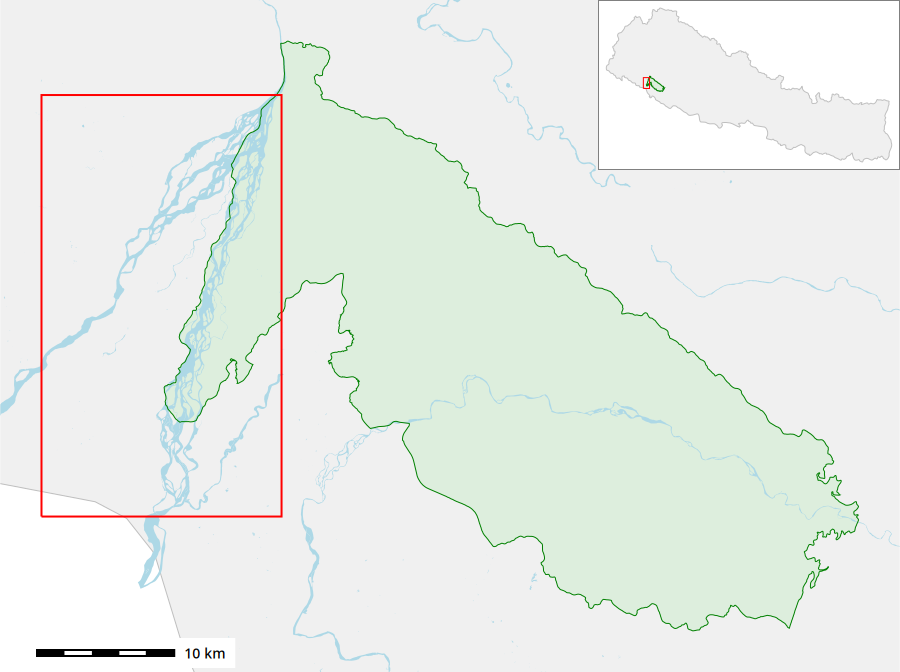

In [35]:
#| label: out01-study-area-map
#| id: out01
#| code-fold: show

import grass.jupyter as gj
from IPython.display import display
from PIL import Image, ImageOps

# Main map: the study area and Bardia National Park, with the water bodies, and a
# margin of 3 km (grow counts cells, here of 100 m)
with gs.RegionManager(vector="Bardia,Karnali_region", res=100, grow=30):
    main_map = gj.Map(width=900, use_region=True)
    main_map.d_vect(map="Nepal", color="191:191:191", fill_color="240:240:240")
    main_map.d_vect(map="Bardia", color="none", fill_color="221:238:221")
    main_map.d_vect(map="osm_water", color="none", fill_color="173:216:230")
    main_map.d_vect(map="Bardia", color="0:128:0", fill_color="none")
    main_map.d_vect(map="Karnali_region", color="red", fill_color="none", width=2)
    main_map.d_barscale(
        style="classic",
        at=(3, 5),
        length=10,
        units="kilometers",
        segment=5,
        fontsize=14,
    )

# Inset: Nepal, with Bardia National Park and the study area, and a margin of 20 km
with gs.RegionManager(vector="Nepal", res=1000, grow=20):
    inset = gj.Map(width=300, use_region=True)
    inset.d_vect(map="Nepal", color="191:191:191", fill_color="240:240:240")
    inset.d_vect(map="Bardia", color="0:128:0", fill_color="221:238:221")
    inset.d_vect(map="Karnali_region", color="red", fill_color="none", width=1)

# The inset, on a white background with a grey border, in the upper right
# corner of the main map
main_image = Image.open(main_map.filename).convert("RGBA")
inset_image = Image.new("RGBA", Image.open(inset.filename).size, "white")
inset_image.alpha_composite(Image.open(inset.filename).convert("RGBA"))
inset_image = ImageOps.expand(inset_image, border=1, fill="grey")
main_image.alpha_composite(inset_image, (main_image.width - inset_image.width, 0))
display(main_image)

## Prepare the download

### CDS S3 key

The first step is to get a list of scenes that we want to download and process. Searching for scenes requires no credentials, but downloading does. We download through the [S3 access](https://documentation.dataspace.copernicus.eu/APIs/S3.html) of the [Copernicus Data Space Ecosystem](https://dataspace.copernicus.eu/), which needs a S3 key. To get these, create an account with the Copernicus Data Space Ecosystem, create the keys in the [S3 credentials manager](https://eodata-s3keysmanager.dataspace.copernicus.eu/), and add them to the eodag configuration file under `cop_dataspace_s3`, as described in the [EODAG documentation](https://eodag.readthedocs.io/en/stable/getting_started_guide/configure.html).

### List available scenes

We use the [`i.eodag`](https://grass.osgeo.org/grass-stable/manuals/addons/i.eodag.html) add-on to search the Copernicus Data Space Ecosystem for Sentinel-2 Level-2A products whose footprints intersect the study area. The `-l` flag instructs `i.eodag` to list the matching products and exit without downloading them. The search results are saved to a GeoJSON file for subsequent filtering and processing.

Setting `clouds=95` limits the search to products with a maximum reported cloud cover of 95%. This value describes cloud cover across the entire 100 × 100 km Sentinel-2 tile rather than within the study area itself. We therefore apply a relatively high threshold, as a tile with extensive cloud cover may still be cloud-free over the study area.

The search returns products from every Sentinel-2 tile whose footprint intersects the study area. Although the study area lies entirely within tile T44RNS, it also intersects the overlapping footprint of the neighboring tile T44RMS. To select only products from T44RNS, we use the `pattern` option, which filters product identifiers using a regular expression. Note that if a study area spans multiple tiles, these can be included using an expression such as `.*_(T44RNS|T44RMS)_.*`.

Because searches covering multiple years may time out, we query the catalogue one calendar year at a time. The resulting annual GeoJSON files are then merged into a single file containing all matching products.

In [ ]:
#| label: dat01-search-scenes
#| id: dat01
#| code-fold: show

import json

# Tile that covers the whole study area; products of other tiles are left out
TILE = "T44RNS"

data_dir = Path("sentinel_data")
data_dir.mkdir(exist_ok=True)

scenes = []
for year in range(2016, 2027):
    search_file = data_dir / f"search_{year}.geojson"
    tools.i_eodag(
        producttype="S2_MSI_L2A",
        provider="cop_dataspace",
        map="Karnali_region@PERMANENT",
        area_relation="Intersects",
        clouds=95,
        pattern=f".*_{TILE}_.*",
        start=f"{year}-01-01",
        end=f"{year}-12-31",
        save=str(search_file),
        limit=10000,
        flags="l",
    )
    year_scenes = json.loads(search_file.read_text())["features"]
    gs.message(f"{year}: found {len(year_scenes)} scenes")
    scenes.extend(year_scenes)

gs.message(f"Found {len(scenes)} scenes in total")

combined_file = data_dir / "search_all.geojson"
combined_file.write_text(json.dumps({"type": "FeatureCollection", "features": scenes}))

You only need to run the search loop once. If you come back to this notebook in a later session, load the scenes from `search_all.geojson` instead of searching again: 

In [36]:
#| label: def04-load-scenes
#| id: def04
#| code-fold: show

import json

data_dir = Path("sentinel_data")
combined_file = data_dir / "search_all.geojson"


def load_scenes(path):
    """Load scene features previously saved by the search loop above."""
    return json.loads(Path(path).read_text())["features"]


scenes = load_scenes(combined_file)
gs.message(f"Loaded {len(scenes)} scenes from {combined_file}")

Loaded 656 scenes from sentinel_data/search_all.geojson


### Group scenes per day

Sentinel-2 data are distributed as 100 × 100 km tiles, with overlaps between tiles and satellite orbits. The study area lies within one orbit, so in general we only have one scene per day. A possible exception is when Sentinel-2A and Sentinel-2C pass over on the same day, along the same orbit, or where two orbits overlap (not the case here). Later, when we compute the NDVI, we combine the scenes of the same day into one map. Here we create a list of the available scenes grouped by day, which also determines the order in which we download and process the data.

The search results may also contain multiple versions of the same acquisition. This occurs when ESA reprocesses a scene using a newer *processing baseline*. For each acquisition, the function below keeps only the version with the highest processing baseline, using the most recent processing date on a tie. It then creates a list in which the remaining scenes are grouped by their acquisition day, discarding the time of day.

In [37]:
#| label: def05-group-days
#| id: def05
#| code-fold: show

from collections import defaultdict


def group_scenes_by_day(features):
    """Group scene features by acquisition day, dropping duplicate versions.

    Scene titles have seven fields, e.g.
    S2B_MSIL2A_20180203T051019_N0500_R019_T44RNS_20230917T032701:
    satellite, product, sensing time, baseline, orbit, tile, processing time.
    """
    best = {}
    for feature in features:
        parts = feature["properties"]["title"].split("_")
        # Same satellite, product, sensing time, orbit and tile = same acquisition
        key = (parts[0], parts[1], parts[2], parts[4], parts[5])
        # Higher baseline wins; on a tie, the later processing time wins
        rank = (int(parts[3][1:]), parts[6])
        if key not in best or rank > best[key][0]:
            best[key] = (rank, feature)

    days = defaultdict(list)
    for _, feature in best.values():
        day = feature["properties"]["start_datetime"][:10]
        days[day].append(feature)
    return dict(sorted(days.items()))


days = group_scenes_by_day(scenes)
gs.message(f"{len(days)} acquisition days")

649 acquisition days


The initial search returned 1,061 scenes. After retaining only the latest processing version of each acquisition and grouping the remaining scenes by date, these correspond to 1,021 unique acquisition days. This is at the time of writing. Your results may differ if run later in the year or when adding subsequent years to the search.

## Example scene

Before importing the full Sentinel-2 time series, we go through the processing step by step with the example scene imported above. We keep the imported bands as they are delivered: integer digital numbers (DN), with clouds and all. The imported data thus remain the source of truth. Choices made later, such as which pixels to remove and how to combine the scenes of one day, can be changed and rerun without downloading the data again. Integer maps also take less disk space than maps with reflectance values.

We prepare the imported bands of the example scene and detect clouds and shadows. We then register the bands, the SCL raster and the cloud mask in space-time raster datasets (STRDS). 

In the next section, the same steps run in a loop over all days, together with downloading and importing, so that only one day's downloaded files are on disk at a time. Because some days have two scenes (see *Group scenes per day*), the functions defined here handle all scenes of a day, although the example has only one.

Note that removing the clouds, converting to reflectance and combining the scenes of one day follow when we compute the NDVI. 

### Download the scene

A Level-2A product is about 1.1 GB, but we only need a few of its files, namely the bands we import, the tile metadata file `MTD_TL.xml`, from which *i.sentinel.import* reads the acquisition time, and the product metadata file `MTD_MSIL2A.xml`, which gives the values needed to convert the bands to reflectance. The *i.eodag* module downloads complete products. We therefore use the eodag Python library directly with the `cop_dataspace_s3` provider. This provider lists each file of a product as an *asset*, after which we can use the `dag.download` function to selects the assets to download. With the assets in `ASSETS`, this reduces the download to about 380 MB per scene. If you import other bands, add their asset names to `ASSETS` as well; you can list the asset names of a product with `product.assets.keys()`.

Our search results come from the `cop_dataspace` provider, so we look up each scene again by its title on `cop_dataspace_s3`. eodag stores the files of a scene in a folder named after the product. Because *i.sentinel.import* expects the folder names to end with `.SAFE`, we add that extension. The `download_day` function below is written for a full day's scene, so it can be reused as-is for the full time series later.

In [ ]:
#| label: def06-download-func
#| id: def06
#| code-fold: show

import shutil

from eodag import EODataAccessGateway

dag = EODataAccessGateway()

# eodag's names of the files we need; keep in line with BAND_PATTERN further on
ASSETS = r"B0[348]|SCL_20m|MTD_(TL|MSIL2A)\.xml"


def download_day(day, features, download_dir):
    """Download the needed files of one day's scenes into an empty download_dir."""
    if download_dir.exists():
        shutil.rmtree(download_dir)
    download_dir.mkdir(parents=True)

    for feature in features:
        title = feature["properties"]["title"]
        # The search results come from cop_dataspace, which only downloads whole
        # products; cop_dataspace_s3 can download the same scene per file
        product = dag.search(
            id=title, provider="cop_dataspace_s3", collection="S2_MSI_L2A"
        )[0]
        product_dir = Path(
            dag.download(product, asset=ASSETS, output_dir=str(download_dir))
        )
        # i.sentinel.import expects the product folders to end with .SAFE
        product_dir.rename(product_dir.with_name(f"{product_dir.name}.SAFE"))

In [39]:
#| label: def07-example-settings
#| id: def07
#| code-fold: show

example_day = "2017-09-06"
example_scene = days[example_day][0]
example_dir = data_dir / "example_scene"

In [ ]:
#| label: dat02-download-example
#| id: dat02
#| code-fold: show

download_day(example_day, [example_scene], example_dir)

### Importing the example scene and aligning the region

We import the green (B03), red (B04) and near-infrared (B08) bands of the example scene, needed for cloud detection and the NDVI, together with the Scene Classification Layer (SCL), the per-pixel quality and cloud mask included in every Level-2A product. With `extent="region"`, only the part within the computational region is imported. The imported bands keep the resolution and alignment of the Sentinel-2 grid; only their extent follows the region. The SCL has a resolution of 20 m, but its cells line up with the 10 m cells of the other bands.

The region defined above has a resolution of 10 m and with the `-a` flag set, it should be properly aligned to the Sentinel-2 grid. In the spirit of better safe than sorry, we align the region to one of the imported bands. We save the result as `karnali_10m` so it can be reused in later sessions and in the full import that follows. 

With `register_output`, *i.sentinel.import* writes a text file that lists, for each imported raster, its name, acquisition time and semantic label. We use this file to keep track of the imported maps. Note that if you want to compute different indices, you need to import the bands required for those indices as well.

In [ ]:
#| label: dat03-clear-register
#| id: dat03
#| code-fold: show

register_example = data_dir / "register_example.txt"
register_example.unlink(missing_ok=True)

In [ ]:
#| label: dat04-import-example
#| id: dat04
#| code-fold: show
tools.i_sentinel_import(
    input=str(example_dir),
    pattern=r"_(B0[348]_10m|SCL_20m)",
    extent="region",
    memory=memory,
    register_output=str(register_example),
    overwrite=overwrite,
)

example_maps = [
    line.split("|")[0] for line in register_example.read_text().splitlines()
]
print("\n".join(example_maps))

red_map = next(name for name in example_maps if "_B04_" in name)
tools.g_region(align=red_map, res=10)
tools.g_region(save="karnali_10m", overwrite=overwrite)
gs.message(f"Region aligned to {red_map}")

You only need to align and save the region once. If you come back to this notebook in a later session, reload the saved region to be sure you are using the right region.

In [40]:
#| label: def08-region-10m
#| id: def08
#| code-fold: show

tools.g_region(region="karnali_10m")

### Labels and colors of the SCL classes

The SCL raster contains class numbers. Below, we define the label and the conventional color of each class. With *r.category*, we attach the [Sentinel-2 L2A class labels](https://sentiwiki.copernicus.eu/web/s2-processing) to the SCL raster. With *r.colors*, we give the SCL raster the color table conventionally used for these classes (e.g. in Sentinel Hub and SNAP).

In [42]:
#| label: def09-scl-categories
#| id: def09
#| code-fold: show

from io import StringIO

SCL_CLASSES = {
    0: "No data",
    1: "Saturated or defective",
    2: "Dark area pixels / cast shadows",
    3: "Cloud shadows",
    4: "Vegetation",
    5: "Not vegetated",
    6: "Water",
    7: "Unclassified",
    8: "Cloud, medium probability",
    9: "Cloud, high probability",
    10: "Thin cirrus",
    11: "Snow or ice",
}
scl_rules = "\n".join(f"{cat}\t{label}" for cat, label in SCL_CLASSES.items())

In [43]:
#| label: def10-scl-colors
#| id: def10
#| code-fold: show

SCL_COLORS = {
    0: "0:0:0",  # No data
    1: "255:0:0",  # Saturated or defective
    2: "47:47:47",  # Dark area pixels / cast shadows
    3: "100:50:0",  # Cloud shadows
    4: "0:160:0",  # Vegetation
    5: "255:230:90",  # Not vegetated
    6: "0:0:255",  # Water
    7: "128:128:128",  # Unclassified
    8: "192:192:192",  # Cloud, medium probability
    9: "255:255:255",  # Cloud, high probability
    10: "100:200:255",  # Thin cirrus
    11: "255:150:255",  # Snow or ice
}
scl_color_rules = "\n".join(f"{cat} {rgb}" for cat, rgb in SCL_COLORS.items()) + "\nend"

In [ ]:
#| label: dat05-scl-apply
#| id: dat05
#| code-fold: show

scl_map = next(
    line.split("|")[0]
    for line in register_example.read_text().splitlines()
    if "_SCL_" in line
)
tools.r_category(map=scl_map, rules=StringIO(scl_rules))
tools.r_colors(map=scl_map, rules=StringIO(scl_color_rules))

### Reading the register files

The register file of *i.sentinel.import* lists, for each imported raster, its name, its acquisition time and its semantic label, e.g. `S2_4` for band B04. *i.sentinel.import* takes the acquisition time from the `SENSING_TIME` in the product's `MTD_TL.xml` file. The map names, e.g. `T44RNS_20180203T051019_B04_10m`, contain the tile, the date and time of the product, the band and the resolution. The function `read_register` below reads the register file. It takes the acquisition time and the semantic label from the register, and the band and the scene from the map name. The acquisition time has a precision of microseconds. We only keep whole seconds, which is precise enough to tell the scenes apart. We come back to the reason when registering the maps.

The steps that follow look up the maps of a scene by band, for example, the red band for the cloud mask. `group_by_scene` therefore collects the maps of each scene, with the band as key. A *scene* is identified by its tile and the date and time of the product, the first part of the map names (e.g. `T44RNS_20180203T051019`). For the example, this gives one scene with its four maps. Grouping by scene matters when we process all days, because some days have two scenes.

In [44]:
#| label: def11-read-register
#| id: def11
#| code-fold: show

import re


def scene_id(map_name):
    """Scene of a map: its tile and acquisition date and time."""
    return re.search(r"T\d{2}[A-Z]{3}_20\d{6}T\d{6}", map_name).group()


def read_register(register_file):
    """Read an i.sentinel.import register file into a list of records."""
    records = []
    for line in Path(register_file).read_text().splitlines():
        if not line.strip():
            continue
        name, start_time, label = line.split("|")[:3]
        band = re.search(r"_(B(?:0[1-9]|1[012]|8A)|SCL)_\d{2}m", name).group(1)
        records.append(
            {
                "map": name,
                # Whole seconds: drop the microseconds (".%f")
                "start_time": start_time[:19],
                "scene": scene_id(name),
                "band": band,
                "label": label,
            }
        )
    return records


def group_by_scene(records):
    """Return {scene: {band: map name}}."""
    scene_maps = defaultdict(dict)
    for record in records:
        scene_maps[record["scene"]][record["band"]] = record["map"]
    return scene_maps

In [ ]:
#| label: dat06-read-register-example
#| id: dat06
#| code-fold: show

example_records = read_register(register_example)
example_scene_maps = group_by_scene(example_records)
for scene, bands in example_scene_maps.items():
    print(scene, sorted(bands))

### Preparing the imported bands

The bands are kept as DN values, but we prepare them in three ways for later analysis:

- The value 0 marks pixels without data, e.g. outside the satellite's swath. We set these to NULL with *r.null*.
- We check that every imported map is an integer (CELL) map.
- With *r.support*, we record the name of the product each map comes from, and for the bands the units and the conversion to reflectance.

The conversion from DN to reflectance is $\text{reflectance} = (DN + \text{BOA\_ADD\_OFFSET}) / \text{QUANTIFICATION\_VALUE}$

All scenes have an offset of −1000 and the quantification value is 10000. Still, to be sure, we use the `check_conversion` function to read for each scene both values from the `MTD_MSIL2A.xml` file. It stops with an error if a product for some reason uses different values.

In [45]:
#| label: def12-dn-conversion
#| id: def12
#| code-fold: show

import xml.etree.ElementTree as ET

# Conversion from DN to reflectance: (DN + BOA_ADD_OFFSET) / QUANTIFICATION_VALUE
BOA_ADD_OFFSET = -1000
QUANTIFICATION_VALUE = 10000


def check_conversion(product_dir):
    """Check that a product uses BOA_ADD_OFFSET and QUANTIFICATION_VALUE."""
    metadata = ET.parse(next(product_dir.rglob("MTD_MSIL2A.xml"))).getroot()
    # One offset per band
    offsets = {int(element.text) for element in metadata.iter("BOA_ADD_OFFSET")}
    quantification = int(next(metadata.iter("BOA_QUANTIFICATION_VALUE")).text)
    if offsets != {BOA_ADD_OFFSET} or quantification != QUANTIFICATION_VALUE:
        raise ValueError(
            f"{product_dir.name}: offsets {offsets} and quantification value "
            f"{quantification}, expected {BOA_ADD_OFFSET} and {QUANTIFICATION_VALUE}"
        )


def prepare_bands(records, product_parent_dir):
    """Check the products, and prepare the imported maps of their scenes."""
    products = {}
    for product_dir in product_parent_dir.glob("*.SAFE"):
        check_conversion(product_dir)
        # e.g. S2B_MSIL2A_20180203T051019_N0500_R019_T44RNS_20230917T032701
        parts = product_dir.stem.split("_")
        products[f"{parts[5]}_{parts[2]}"] = product_dir.stem

    for record in records:
        name = record["map"]
        datatype = tools.r_info(map=name, format="json").json["datatype"]
        if datatype != "CELL":
            raise TypeError(f"{name} is a {datatype} map, expected CELL (integer)")
        if record["band"] == "SCL":
            tools.r_support(map=name, source1=products[record["scene"]])
        else:
            tools.r_null(map=name, setnull=0)
            tools.r_support(
                map=name,
                source1=products[record["scene"]],
                units="DN",
                description=(
                    f"Reflectance = (DN {BOA_ADD_OFFSET:+d}) / {QUANTIFICATION_VALUE}"
                ),
            )

In [ ]:
#| label: dat07-prepare-example
#| id: dat07
#| code-fold: show

prepare_bands(example_records, example_dir)

### Detecting clouds and shadows with OmniCloudMask

Clouds and cloud shadows are the main source of noise in optical time series. The SCL includes cloud and shadow classes, but here we use [OmniCloudMask](https://github.com/DPIRD-DMA/OmniCloudMask) by default, a deep learning model for the detection of clouds and cloud shadows. It only needs the red, green and near-infrared bands.

The addon *i.omnicloudmask* runs the model on GRASS raster maps. It creates a raster with four classes: 0 (clear), 1 (thick cloud), 2 (thin cloud) and 3 (cloud shadow), and gives these classes labels and colors. We create one mask per scene. *i.omnicloudmask* treats NULL in the bands as no data, so the pixels outside the swath are not classified.

In [46]:
#| label: def13-omnicloud
#| id: def13
#| code-fold: show

def cloud_mask(scene, bands):
    """Create the OmniCloudMask cloud and shadow map of one scene.

    bands: {band: map name} of the scene.
    """
    output = f"{scene}_omnicloud"
    tools.i_omnicloudmask(
        red=bands["B04"],
        green=bands["B03"],
        nir=bands["B08"],
        output=output,
        nprocs=nprocs,
        memory=memory,
        overwrite=overwrite,
    )
    return output

In [ ]:
#| label: dat08-omnicloud-example
#| id: dat08
#| code-fold: show

example_masks = {
    scene: cloud_mask(scene, bands) for scene, bands in example_scene_maps.items()
}

The maps below show band B03 of the example scene. To better visualize the clouds, the grey color table using histogram equalization is used. On top, the left map shows the clouds and shadows found by OmniCloudMask (classes 1 to 3), and the middle map the cloud and shadow classes of the SCL (3, 8, 9 and 10). The right map shows the band without a mask.

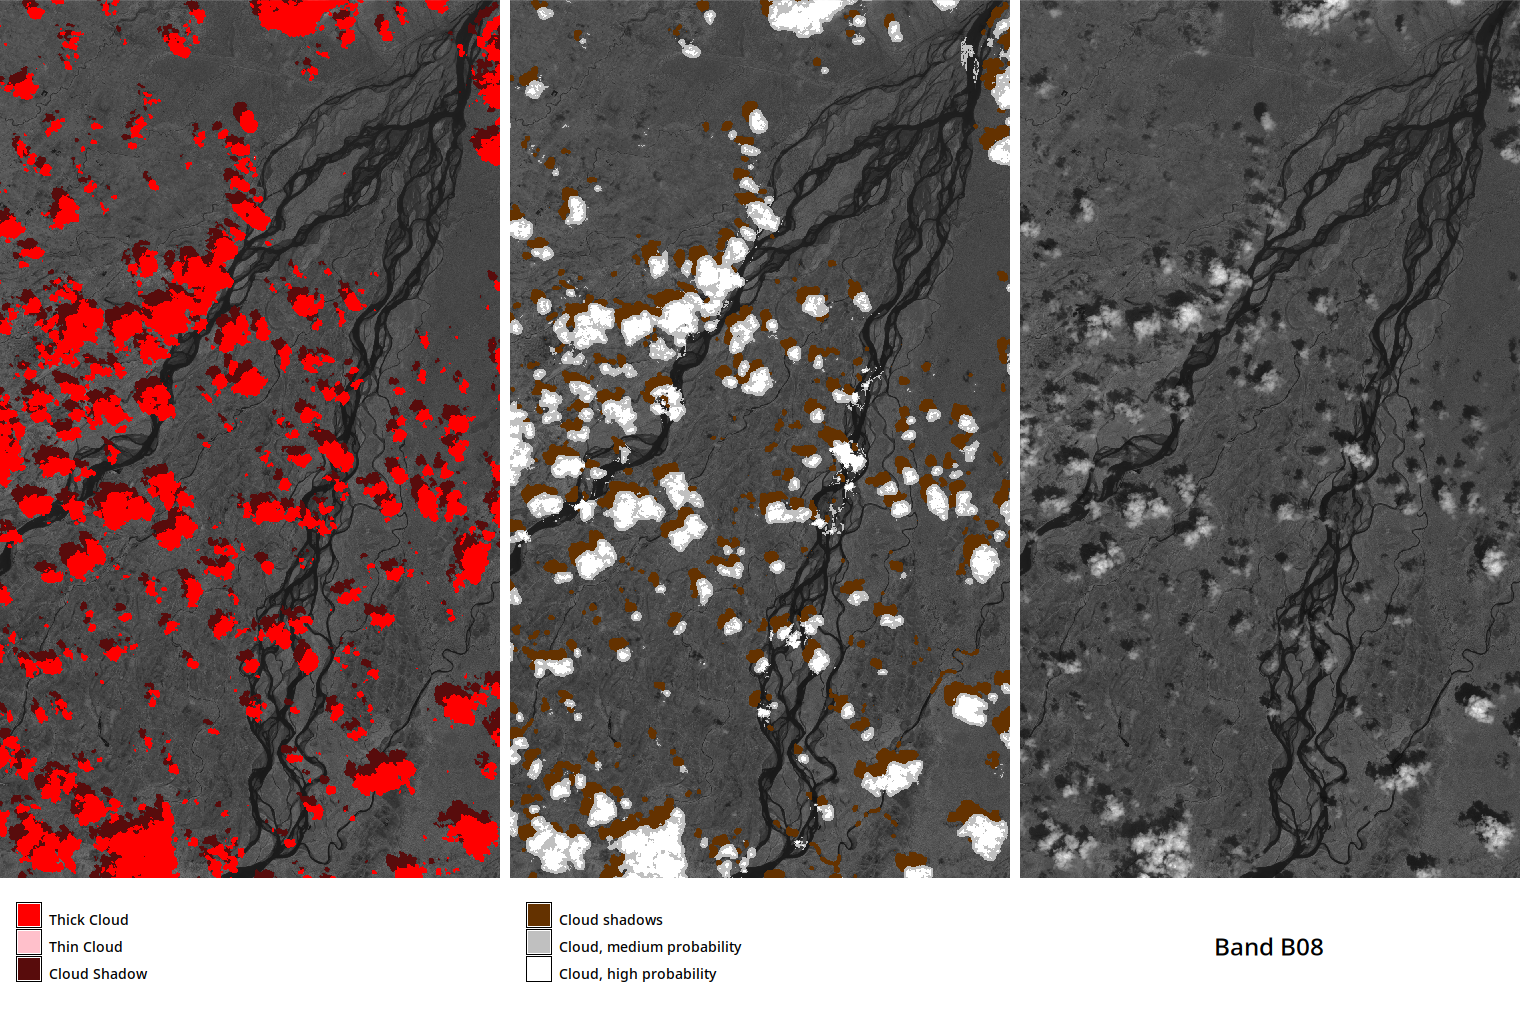

In [47]:
#| label: out02-show-example
#| id: out02
#| code-fold: show

from io import StringIO

import grass.jupyter as gj
from IPython.display import display
from PIL import Image

# Map names of the example scene, e.g. T44RNS_20170906T050649_B08_10m, made from
# the tile and sensing time in the product name
parts = example_scene["properties"]["title"].split("_")
scene = f"{parts[5]}_{parts[2]}"
b08 = f"{scene}_B08_10m"
scl = f"{scene}_SCL_20m"
omnicloud = f"{scene}_omnicloud"


def legend_region(fraction=0.15):
    """Return what is needed to draw a legend in a strip under a map.

    Returns a region manager that extends the region to the south by fraction of
    its height (in whole rows), the d.graph polygon that covers this strip, and
    the height of the strip, both in percentages of the map image.
    """
    region = gs.region()
    rows = round(fraction * region["rows"])
    south = region["s"] - rows * region["nsres"]
    height = 100 * rows / (region["rows"] + rows)
    strip = StringIO(f"polygon\n0 0\n0 {height}\n100 {height}\n100 0\n")
    return gs.RegionManager(s=south), strip, height


def side_by_side(displays, gap=10):
    """Return the images of gj.Map displays next to each other, as one image."""
    images = [Image.open(item.filename) for item in displays]
    width = sum(image.width for image in images) + gap * (len(images) - 1)
    height = max(image.height for image in images)
    combined = Image.new("RGBA", (width, height), "white")
    x = 0
    for image in images:
        combined.paste(image, (x, 0))
        x += image.width + gap
    return combined


def mask_display(mask, values):
    """Return a map of band B08 with the given mask classes on top and their legend."""
    region, strip, height = legend_region()
    with region:
        mask_map = gj.Map(width=500, use_region=True)
        mask_map.d_rast(map=b08)
        mask_map.d_rast(map=mask, values=values)
        mask_map.d_graph(color="white", stdin=strip)
        mask_map.d_legend(
            raster=mask, use=values, flags="c", at=(1, height - 1, 3, 97), fontsize=14
        )
    return mask_map


# Band B08 with the OmniCloudMask clouds and shadows, band B08 with the SCL cloud
# and shadow classes, and band B08 only
omnicloud_display = mask_display(omnicloud, "1,2,3")
scl_display = mask_display(scl, "3,8,9")
region, strip, height = legend_region()
with region:
    b08_display = gj.Map(width=500, use_region=True)
    b08_display.d_rast(map=b08)
    b08_display.d_graph(color="white", stdin=strip)
    b08_display.d_text(
        text="Band B08", at=(50, height / 2), align="cc", size=3, color="black"
    )

display(side_by_side([omnicloud_display, scl_display, b08_display]))

In this example, the two approaches produce broadly similar results. OmniCloudMask is slightly more conservative in some areas, whereas elsewhere the SCL additionally masks pixels classified as having a medium probability of cloud.

### Registering the maps in the temporal database

The GRASS temporal framework manages time series of maps as *space-time datasets*. A space-time raster dataset (STRDS) holds references to raster maps together with their timestamps. Tools for time series analysis, aggregation and temporal algebra work on these datasets, so we can handle hundreds of maps as one object.

We create one STRDS per layer: `sentinel2_B03`, `sentinel2_B04` and `sentinel2_B08` for the bands, `sentinel2_SCL` for the SCL rasters and `sentinel2_omnicloud` for the cloud masks. When computing the NDVI, *t.rast.mapcalc* takes the maps with the same timestamp from each STRDS. Matching by time guarantees that the bands and masks used together belong to the same scene. Each map also gets a *semantic label*, e.g., `S2_4` for band B04, which describes what the map contains.

*t.rast.mapcalc* only matches maps of different STRDS when the maps have a time interval, not a single point in time. We therefore give each scene an interval of one second, starting at its acquisition time. This is also why we keep whole seconds only: *t.rast.aggregate*, which we use to combine the scenes of a day, would otherwise carry the fraction of a second over to the start time of the daily maps.

The STRDS only need to be created once; `create_strds` leaves an existing STRDS, e.g., from an earlier session, as it is.

In [49]:
#| label: def14-register-strds
#| id: def14
#| code-fold: show

from datetime import datetime, timedelta

OMNICLOUD_STRDS = "sentinel2_omnicloud"


def band_strds(band):
    """Name of the STRDS of a band, or of the SCL rasters (band "SCL")."""
    return f"sentinel2_{band}"


def create_strds(name, title, description):
    """Create an STRDS in the current mapset, unless it exists already."""
    existing = tools.t_list(
        type="strds", columns="name", format="json", mapset=gs.gisenv()["MAPSET"]
    ).json
    if name not in [row["name"] for row in existing]:
        tools.t_create(
            type="strds",
            temporaltype="absolute",
            output=name,
            title=title,
            description=description,
        )


def time_interval(start_time):
    """Return 'start|end' for an interval of one second from start_time."""
    end_time = datetime.fromisoformat(start_time) + timedelta(seconds=1)
    return f"{start_time}|{end_time:%Y-%m-%d %H:%M:%S}"


def register(strds, lines):
    """Register maps in an STRDS, given lines of name|start|end[|semantic label]."""
    register_file = gs.tempfile()
    Path(register_file).write_text("\n".join(lines) + "\n")
    tools.t_register(input=strds, file=register_file, separator="pipe", overwrite=True)


def register_scenes(records, masks):
    """Register the bands, SCL rasters and cloud masks of the scenes."""
    lines = defaultdict(list)
    for record in records:
        band = record["band"]
        interval = time_interval(record["start_time"])
        lines[band].append(f"{record['map']}|{interval}|{record['label']}")
        if band == "SCL":
            lines["omnicloud"].append(f"{masks[record['scene']]}|{interval}")

    for layer, layer_lines in lines.items():
        if layer == "omnicloud":
            strds = OMNICLOUD_STRDS
            title = "OmniCloudMask per scene"
            description = "OmniCloudMask clouds and shadows of each Sentinel-2 scene"
        elif layer == "SCL":
            strds = band_strds(layer)
            title = "Sentinel-2 SCL per scene"
            description = "Sentinel-2 L2A Scene Classification Layer of each scene"
        else:
            strds = band_strds(layer)
            title = f"Sentinel-2 {layer} per scene"
            description = f"Sentinel-2 L2A band {layer} of each scene, as DN values"
        create_strds(strds, title, description)
        register(strds, layer_lines)

In [ ]:
#| label: dat09-register-example
#| id: dat09
#| code-fold: show

register_scenes(example_records, example_masks)

### Cleaning up

Finally, we remove the downloaded example scene. The imported maps are kept: they are registered in the STRDS. The example day is now fully processed, so we add it to `done_days.json`, together with its scenes. The loop in the next section skips the days in this file.

In [50]:
#| label: def15-done-days
#| id: def15
#| code-fold: show

done_days_file = data_dir / "done_days.json"


def load_done_days():
    """Return {day: scenes} of the days processed so far."""
    return json.loads(done_days_file.read_text()) if done_days_file.exists() else {}


def mark_done(day, scenes):
    """Add a processed day, with its scenes."""
    done_days = load_done_days()
    done_days[day] = scenes
    done_days_file.write_text(json.dumps(done_days, indent=2))

In [ ]:
#| label: dat10-done-example
#| id: dat10
#| code-fold: show

shutil.rmtree(example_dir, ignore_errors=True)
mark_done(example_day, list(example_scene_maps))

## Processing all days

The functions defined above are combined into the `process_day` function. It downloads, imports, prepares, creates cloud masks, and registers one day, and then removes the downloaded files. We repeat this for all available days.

Each day's SCL raster gets the class labels and colors defined earlier. We only import the green, red and near-infrared bands and the SCL, the bands needed for cloud detection and the NDVI. If you want to compute a different index, adapt `BAND_PATTERN` below, and `ASSETS` in the cell defining `download_day`, to download and import the bands it needs. We reuse the same `download_dir` for every day, and remove it when the loop is done.

Processing the full time series takes a long time, so the loop is written to be stopped and resumed. After each processed day, it adds that day, with its scenes, to `done_days.json`; when you run the cell again, even in a new session, those days are skipped. A day that is interrupted halfway is processed again from scratch, overwriting the maps it left behind and registering them again; this needs `overwrite = True`. A problem with one day (e.g., a failed download) is reported and added to `failed_days.json`, but does not stop the loop over the remaining days. Interrupting the notebook, on the other hand, does stop the loop.

In [51]:
#| label: def16-process-day
#| id: def16
#| code-fold: show

from grass.tools import ToolError

BAND_PATTERN = r"_(B0[348]_10m|SCL_20m)"

download_dir = data_dir / "download"
failed_days_file = data_dir / "failed_days.json"


def process_day(day, features):
    """Download, import, prepare, cloud mask and register one day.

    Returns the scenes of the day.
    """
    download_day(day, features, download_dir)
    register_raw = data_dir / f"register_raw_{day}.txt"
    register_raw.unlink(missing_ok=True)
    tools.i_sentinel_import(
        input=str(download_dir),
        pattern=BAND_PATTERN,
        extent="region",
        memory=memory,
        register_output=str(register_raw),
        # i.sentinel.import does not fail on existing maps, but silently keeps
        # them; set overwrite is True toreplace maps left behind by an earlier
        # interrupted attempt
        overwrite=True,
    )
    records = read_register(register_raw)
    prepare_bands(records, download_dir)

    for record in records:
        if record["band"] == "SCL":
            tools.r_category(map=record["map"], rules=StringIO(scl_rules))
            tools.r_colors(map=record["map"], rules=StringIO(scl_color_rules))

    scene_maps = group_by_scene(records)
    masks = {scene: cloud_mask(scene, bands) for scene, bands in scene_maps.items()}
    register_scenes(records, masks)
    register_raw.unlink()
    return list(scene_maps)

In [ ]:
#| label: dat11-process-all
#| id: dat11
#| code-fold: show

done_days = load_done_days()
failed_days = []
failed_days_file.write_text(json.dumps(failed_days))

for day, features in days.items():
    if day in done_days:
        continue
    try:
        scenes = process_day(day, features)
    except Exception as error:
        # A negative return code means the tool was killed by a signal, e.g.
        # by interrupting the notebook: stop the loop instead of moving on
        if isinstance(error, ToolError) and error.returncode < 0:
            raise
        gs.warning(f"{day}: failed ({error})")
        failed_days.append(day)
        failed_days_file.write_text(json.dumps(failed_days))
    else:
        mark_done(day, scenes)

shutil.rmtree(download_dir, ignore_errors=True)
gs.message(f"{len(load_done_days())} of {len(days)} day(s) processed")
summary = f"{len(failed_days)} day(s) failed; saved to {failed_days_file}"
if failed_days:
    gs.warning(summary)
else:
    gs.message(summary)

### Retrying failed days

A failed day is usually transient (a timeout, a server hiccup). Because the loop above skips the days in `done_days.json`, retrying failed days is a matter of running that cell again, even in a new session: it tries again only the days that are not done yet. `failed_days.json` then lists the days that failed in this latest run.

## Computing the NDVI

We compute the NDVI for each scene with *t.rast.mapcalc*, the temporal version of *r.mapcalc*, and then combine the scenes of the same day. *t.rast.mapcalc* takes, for each timestamp, the matching maps of the input STRDS. One expression removes the unusable pixels, converts the bands to reflectance and computes the NDVI. To compute a different index, you need to change the expression.

### Switching to the ndvi mapset

The NDVI goes into a mapset of its own, `ndvi`. We create the mapset and switch to it with *g.mapset*. Next, we set the region saved in the `sentinel2` mapset.

From the `ndvi` mapset, we refer to the STRDS in the `sentinel2` mapset by their full name, e.g. `sentinel2_B04@sentinel2`. *t.rast.mapcalc* replaces the STRDS names in the expression by the names of the maps, so in the expression, `sentinel2_B04@sentinel2` becomes, e.g., `T44RNS_20180203T051019_B04_10m@sentinel2`. Note that the remaining cells of the notebook run in the `ndvi` mapset. To process more days afterward in the same session, switch back first with `tools.g_mapset(mapset=MAPSET)`.

In [54]:
#| label: def17-ndvi-mapset
#| id: def17
#| code-fold: show

NDVI_MAPSET = "ndvi"

tools.g_mapset(mapset=NDVI_MAPSET, flags="c")
tools.g_region(region=f"karnali_10m@{MAPSET}")


def sentinel2_strds(name):
    """Full name of an STRDS in the sentinel2 mapset."""
    return f"{name}@{MAPSET}"

### Checking that the STRDS match

*t.rast.mapcalc* uses the timestamps of the first input STRDS, and looks up the maps with the same timestamp in the other STRDS. A scene that is missing from one of the other STRDS, e.g. after an interrupted run, is skipped without a warning. Two maps with the same timestamp in one STRDS would be a problem as well: *t.rast.mapcalc* would use only one of them. Before computing the NDVI, we therefore check that every input STRDS has the same timestamps, and every timestamp only once.

In [55]:
#| label: def18-check-timestamps
#| id: def18
#| code-fold: show

def check_timestamps(strds_list):
    """Check that the STRDS have the same, unique, timestamps."""
    reference = None
    for strds in strds_list:
        rows = tools.t_rast_list(input=strds, columns="start_time", format="json")
        times = [row["start_time"] for row in rows.json["data"]]
        if len(set(times)) < len(times):
            raise ValueError(f"{strds} has more than one map with the same timestamp")
        if reference is None:
            reference = set(times)
        elif set(times) != reference:
            raise ValueError(f"{strds} and {strds_list[0]} have different timestamps")

In [ ]:
#| label: out03-check-timestamps
#| id: out03
#| code-fold: show

ndvi_inputs = [
    sentinel2_strds(name)
    for name in (
        band_strds("B04"),
        band_strds("B08"),
        band_strds("SCL"),
        OMNICLOUD_STRDS,
    )
]
check_timestamps(ndvi_inputs)

### Converting to reflectance

Sentinel-2 Level-2A products store surface reflectance as integer digital numbers (DN), rather than directly as values between 0 and 1. The conversion is:

$$
\text{reflectance} = \frac{DN + \text{BOA\_ADD\_OFFSET}}{\text{QUANTIFICATION\_VALUE}} = \frac{DN - 1000}{10000}
$$

The values −1000 and 10000 are checked for each product when we prepare the bands. The additive offset of −1000 means that DN values below 1000 produce negative reflectance values. Such values can occur over dark surfaces, for example water in the near-infrared. We therefore clip negative reflectance values to zero. The function below writes this conversion as an *r.mapcalc* expression.

In [56]:
#| label: def19-reflectance
#| id: def19
#| code-fold: show

def reflectance(band):
    """r.mapcalc expression converting a band from DN to reflectance, 
       while clipping at 0."""
    return f"max(({band} + ({BOA_ADD_OFFSET})) / {float(QUANTIFICATION_VALUE)}, 0)"

### Which pixels to remove

The bands themselves are not changed: we decide here which pixels are unusable, and leave them out when computing the NDVI. A pixel is removed when:

- OmniCloudMask flags it as thick cloud, thin cloud or cloud shadow (classes 1-3);
- the SCL classifies it as no data, saturated or defective, or snow or ice (classes 0, 1 and 11), problems OmniCloudMask does not look for.

Pixels without data in a band are NULL, and therefore drop out of any calculation by themselves. The SCL's own cloud and shadow classes (3, 8, 9 and 10) are not used by default. Set `use_scl_clouds = True` to remove these as well, in addition to the clouds and shadows found by OmniCloudMask.

The function below writes these rules as one *r.mapcalc* condition, which is true for the pixels to remove. The `|||` and `&&&` operators are the NULL-tolerant forms of `||` and `&&`: `true ||| NULL` is true, and `false &&& NULL` is false. As a result, a NULL in the OmniCloudMask raster counts as clear, while a NULL in the SCL raster counts as no data. The SCL has a resolution of 20 m, which is resampled on the fly using the nearest neighbor method.

In [57]:
#| label: def20-remove-condition
#| id: def20
#| code-fold: show

# SCL classes that are always removed: no data, 
# saturated or defective, snow or ice
SCL_REMOVE = [0, 1, 11]
# SCL cloud and shadow classes: cloud shadows, cloud (medium 
# and high probability) and thin cirrus; only removed when 
# use_scl_clouds is True
SCL_CLOUDS = [3, 8, 9, 10]
use_scl_clouds = False


def remove_condition(scl, mask):
    """r.mapcalc condition that is true for the pixels to remove.

    scl: the SCL raster, mask: the OmniCloudMask raster of the same scene.
    """
    scl_classes = SCL_REMOVE + (SCL_CLOUDS if use_scl_clouds else [])
    scl_test = " ||| ".join(f"{scl} == {cls}" for cls in scl_classes)
    return f"((!isnull({mask}) &&& {mask} > 0) ||| isnull({scl}) ||| {scl_test})"

### Fraction of removed pixels

Some scenes are completely or nearly completely covered by clouds over the study area. They yield no or very few usable pixels, and the few remaining clear pixels are less reliable, because of edge effects of the detection algorithm along cloud borders. When computing the NDVI, we therefore leave out scenes in which 99% or more of the pixels would be removed. We compute this fraction for each scene with the rules defined above, so after changing `use_scl_clouds`, rerunning the cells of this section is enough.

The fraction is calculated only within the part of the region covered by the scene, i.e., the pixels where, e.g., band B04 is not NULL. For each of these pixels, the *t.rast.mapcalc* expression assigns 1 when the pixel would be removed and 0 otherwise. *t.rast.univar* then gives the mean of each map, which is the removed fraction of the scene. A scene without any data in the region gives a map with only NULL values, which *t.rast.mapcalc* does not keep; such a scene gives no NDVI map either. The resulting STRDS is only needed for the fractions, so we remove it afterwards. We save the removed fraction of each scene in `removed_per_scene.csv`, in the `sentinel_data` folder.

In [58]:
#| label: def21-removed-fraction
#| id: def21
#| code-fold: show

def removed_fractions():
    """Return {start time: removed fraction} of the scenes in the region."""
    b04 = sentinel2_strds(band_strds("B04"))
    scl = sentinel2_strds(band_strds("SCL"))
    mask = sentinel2_strds(OMNICLOUD_STRDS)
    condition = remove_condition(scl, mask)
    tools.t_rast_mapcalc(
        inputs=[b04, scl, mask],
        expression=f"removed = if(isnull({b04}), null(), if({condition}, 1, 0))",
        output="removed",
        basename="removed",
        nprocs=nprocs,
        overwrite=overwrite,
    )
    stats = tools.t_rast_univar(input="removed", format="json", nprocs=nprocs).json
    tools.t_remove(inputs="removed", flags="df")
    return {row["start"]: row["mean"] for row in stats}

In [ ]:
#| label: dat12-removed-fraction
#| id: dat12
#| code-fold: show

import csv

fractions = removed_fractions()

# Scene of each start time, from the names of the B04 maps
rows = tools.t_rast_list(
    input=sentinel2_strds(band_strds("B04")), columns="name,start_time", format="json"
).json["data"]
scenes = {row["start_time"]: scene_id(row["name"]) for row in rows}

with open(data_dir / "removed_per_scene.csv", "w", newline="") as file:
    writer = csv.writer(file)
    writer.writerow(["scene", "start_time", "removed_fraction"])
    for start, fraction in sorted(fractions.items()):
        writer.writerow([scenes[start], start, fraction])

### Leaving out (nearly) fully masked scenes

The scenes in which `max_removed_fraction` (99%) or more of the pixels would be removed are left out. *t.rast.mapcalc* selects maps by timestamp, so we leave these scenes out with a `where` condition on their start time. The fractions are read from `removed_per_scene.csv`, so in a later session there is no need to compute them again. After changing `use_scl_clouds` or processing more days, rerun the cells of the previous section first.

In [59]:
#| label: def22-filter-masked
#| id: def22
import csv

max_removed_fraction = 0.99

# Removed fraction of each scene, saved when computing the fractions
with open(data_dir / "removed_per_scene.csv", newline="") as file:
    fractions = {
        row["start_time"]: float(row["removed_fraction"])
        for row in csv.DictReader(file)
    }

leave_out = [
    f"'{start}'"
    for start, fraction in fractions.items()
    if fraction >= max_removed_fraction
]
gs.message(f"Leaving out {len(leave_out)} of {len(fractions)} scenes")
ndvi_where = f"start_time NOT IN ({', '.join(leave_out)})" if leave_out else None

Leaving out 58 of 650 scenes


With the settings above, 58 of the 650 available scenes are left out when computing the NDVI layers. Note that your numbers may differ, e.g., when new scenes have become available since.

In [60]:
#| label: out04-removed-table
#| id: out04
#| code-fold: show

import pandas as pd
from itables import show

removed_table = pd.read_csv(data_dir / "removed_per_scene.csv")
left_out = removed_table["removed_fraction"] >= max_removed_fraction
percent = 100 * removed_table.pop("removed_fraction")
removed_table["removed_percent"] = percent.round(1)
removed_table["left_out"] = left_out.map({True: "yes", False: "no"})
show(
    removed_table,
    pageLength=10,
    layout={"top1": "searchBuilder"},
    style="table-layout:auto;width:100%;caption-side:bottom",
    columnDefs=[
        {"className": "dt-center", "targets": [2, 3]},
        {"className": "dt-left", "targets": [0, 1]},
    ],
)

### NDVI per scene

The expression sets the pixels to remove to NULL, and computes the NDVI from the reflectance of the red (B04) and near-infrared (B08) bands for the other pixels. The result is stored in single precision (FCELL). Maps that contain only NULL values are not kept.

In [ ]:
#| label: dat13-ndvi-scene
#| id: dat13
red = reflectance(sentinel2_strds(band_strds("B04")))
nir = reflectance(sentinel2_strds(band_strds("B08")))
condition = remove_condition(
    sentinel2_strds(band_strds("SCL")), sentinel2_strds(OMNICLOUD_STRDS)
)

tools.t_rast_mapcalc(
    inputs=ndvi_inputs,
    expression=(
        f"ndvi_scene = if({condition}, null(), float(({nir} - {red}) / ({nir} + {red})))"
    ),
    where=ndvi_where,
    output="ndvi_scene",
    basename="ndvi_scene",
    nprocs=nprocs,
    overwrite=overwrite,
)

### Combining the scenes of one day

With *t.rast.aggregate*, we combine the NDVI maps of each day into one map, using the median of the scenes for each pixel and ignoring NULL values. On days with only one scene, the result equals the NDVI of that scene. The daily maps are named after their day, e.g., `ndvi_2025_05_11`, and registered in the STRDS `ndvi_daily`. The NDVI per scene can be recomputed at any time, so we remove it afterwards. As last step, we assign the ndvi color table to the NDVI layers.

In [ ]:
#| label: dat14-ndvi-daily
#| id: dat14
tools.t_rast_aggregate(
    input="ndvi_scene",
    output="ndvi_daily",
    basename="ndvi",
    granularity="1 day",
    method="median",
    suffix="gran",
    nprocs=nprocs,
    overwrite=overwrite,
)
tools.t_remove(inputs="ndvi_scene", flags="df")
tools.t_rast_colors(input="ndvi_daily", color="ndvi")

The bar chart shows, for each year, the number of days with an NDVI map in `ndvi_daily`. A day has an NDVI map when at least one of its scenes was not left out and has usable pixels.

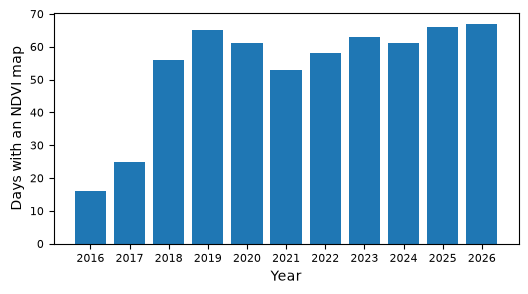

In [61]:
#| label: out05-days-per-year
#| id: out05
#| code-fold: show

import matplotlib.pyplot as plt
import pandas as pd

rows = tools.t_rast_list(
    input="ndvi_daily", columns="start_time", format="json"
).json["data"]
start_times = pd.to_datetime([row["start_time"] for row in rows])
days_per_year = start_times.year.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(days_per_year.index, days_per_year.values)
ax.set_xticks(days_per_year.index)
ax.set_xlabel("Year", fontsize=10)
ax.set_ylabel("Days with an NDVI map", fontsize=10)
ax.tick_params(labelsize=8) 
plt.show()

The results show that relatively few observation dates are available for 2016 and 2017. Consequently, time-series estimates for these years are based on fewer observations and should be interpreted with caution.

## Changing floodplains

Floodplains are highly dynamic landscapes, where floods and shifting channels can redirect or reset vegetation succession. In the Karnali floodplain, an extreme two-peaked monsoon flood in 2009 initiated a gradual flow shift from the eastern Geruwa branch, which supplies Bardia National Park with freshwater, to the western Kauriala branch ([Gautam et al., 2026](https://doi.org/10.5194/esurf-14-887-2026)). This altered parts of the Geruwa floodplain, where grassland, shrub, and woody vegetation expanded ([Vashistha et al., 2021](https://www.nature.com/articles/s41598-021-84143-7); [Gautam et al., 2026](https://doi.org/10.5194/esurf-14-887-2026)). We investigate whether this shift still influences floodplain vegetation and whether ongoing dynamics can be detected using Sentinel-2 time series.

The Global Surface Water dataset describes changes in surface-water occurrence from 1984 to 2024, while NDVI captures vegetation dynamics from 2016 to 2026. By decomposing NDVI time series for areas within each GSW transition class, we examine whether different water histories are associated with distinct vegetation trends and seasonal cycles. For example, do areas that lost water show a gradual increase in NDVI?

### Surface water transitions

The GSW dataset ([Pekel et al., 2016](https://www.nature.com/articles/nature20584)) maps the presence of surface water at 30 m resolution, based on the Landsat archive since 1984. Its *transitions* layer (version 1.5) compares the water state in the first (1984) and the last (2024) years of observation. The classes distinguish water that remained (permanent, seasonal), water that appeared (new permanent, new seasonal) or disappeared (lost permanent, lost seasonal), changes between permanent and seasonal water, and ephemeral water that was present in between, but neither in the first nor in the last year.

| Class | Description |
|---|---|
| 1 Permanent | Permanent water in both the first and the last year |
| 2 New permanent | No water in the first year, permanent water in the last |
| 3 Lost permanent | Permanent water in the first year, no water in the last |
| 4 Seasonal | Seasonal water in both the first and the last year |
| 5 New seasonal | No water in the first year, seasonal water in the last |
| 6 Lost seasonal | Seasonal water in the first year, no water in the last |
| 7 Seasonal to permanent | Seasonal water in the first year, permanent in the last |
| 8 Permanent to seasonal | Permanent water in the first year, seasonal in the last |
| 9 Ephemeral permanent | No water in the first and last year, but permanent water in some years in between |
| 10 Ephemeral seasonal | No water in the first and last year, but seasonal water in some years in between |

We import the tile that covers the study area (80–90°E, 20–30°N) directly from the JRC server (data source: EC JRC/Google) into the PERMANENT mapset. The `/vsicurl/` prefix lets GDAL read only the part of the tile that falls within the region, so the full tile is not downloaded. The map is reprojected to the 10 m grid of the NDVI maps, using nearest neighbour resampling to keep the class values. Class 0 (no water) is set to null, and the classes get the colors and labels of the GSW legend. The report lists the area of each class within the region.

In [62]:
#| label: def23-gswe-classes
#| id: def23
#| code-fold: show

# Value, color and label of the transition classes
gswe_classes = [
    (1, "0:0:221", "Permanent"),
    (2, "33:177:76", "New permanent"),
    (3, "147:7:62", "Lost permanent"),
    (4, "153:217:234", "Seasonal"),
    (5, "181:229:29", "New seasonal"),
    (6, "235:179:186", "Lost seasonal"),
    (7, "255:139:55", "Seasonal to permanent"),
    (8, "254:221:102", "Permanent to seasonal"),
    (9, "127:127:127", "Ephemeral permanent"),
    (10, "172:172:172", "Ephemeral seasonal"),
]

In [ ]:
#| label: dat15-gswe-import
#| id: dat15
#| code-fold: show

from io import StringIO

# Download to permanent
tools.g_mapset(mapset="PERMANENT")
tools.g_region(region="karnali_10m")

# Download url
gswe_url = (
    "/vsicurl/https://s3.waw4-1.cloudferro.com/swift/v1/global-surface-water/"
    "download2024/Aggregated/VER1-5/transitions/transitions_80E_30N_v1_5_2024.tif"
)
tools.r_import(
    input=gswe_url,
    output="gswe_transitions",
    extent="region",
    resolution="region",
    resample="nearest",
    overwrite=overwrite,
)
tools.r_null(map="gswe_transitions", setnull=0)
tools.r_support(
    map="gswe_transitions",
    title="GSW water transitions 1984-2024",
    source1="EC JRC/Google, Global Surface Water v1.5",
)

tools.r_colors(
    map="gswe_transitions",
    rules=StringIO("\n".join(f"{value} {color}" for value, color, _ in gswe_classes)),
)
tools.r_category(
    map="gswe_transitions",
    separator=":",
    rules=StringIO("\n".join(f"{value}:{label}" for value, _, label in gswe_classes)),
)
print(tools.r_report(map="gswe_transitions", units="c,h", flags="n").text)

### Decomposing the NDVI time series

The transition classes show where the water regime changed, but not how the vegetation responded. For that, we use the NDVI time series we constructed above. The NDVI time series of a pixel or area combines a seasonal pattern that returns every year, a slower change over the years, and irregular fluctuations. In general, the seasonal pattern is much larger than the change over the years, which makes the latter difficult to see in the raw time series. STL (*Seasonal-Trend decomposition using LOESS*) separates these components ([Cleveland et al., 1990](https://www.math.unm.edu/~lil/Stat581/STL.pdf)):

$$
\text{observed} = \text{trend} + \text{seasonal} + \text{residual}
$$

**trend**: the slow upward or downward movement over the whole period, independent of the seasonal cycle. It shows long-term change, such as a gradual increase in NDVI during succession, or multi-year patterns.

**seasonal**: the pattern that returns every year. Its values are not NDVI values, but show how far the NDVI is above or below the trend because of the season. STL lets this pattern change slowly over the years, so we can see whether the amplitude or shape of the seasonal cycle changes.

**residual**: what remains after removing the trend and the seasonal pattern. Values around zero mean that the NDVI is about as expected. Peaks and dips show unexpected deviations. These may be ecologically relevant (mowing, flooding, drought), but may also be noise, such as a missed cloud or cloud shadow.

We use the *t.rast.stl* addon to carry out this analysis. The module extracts the time series of a point or area from a STRDS, resamples it to a regular time axis, runs the STL decomposition, and plots the components. For an area, the pixel values at each time step are summarized with a user-selected statistic. We use the median. With the `-d` flag, the plot also shows the interquartile range (25th–75th percentile) around the median.

Optionally, *t.rast.stl* fits a trend line to the deseasonalized series. With the `-s` flag, it fits a Theil-Sen line, i.e., the median slope between all pairs of points, which is robust to outliers. It also reports the p-value of the Mann-Kendall test for a consistent upward or downward trend. In addition, it fits a monotone GAM, which is more suitable to show for non-lineair changes.

We compare the Geruwa and Kauriala branches for three groups of transition classes: areas that lost, gained, or kept water. For each group, we show one class that covers a large area in both branches. The code at the end of this section creates the plots for all classes.

In [63]:
#| label: def24-gswe-areas
#| id: def24
#| code-fold: show

# Back to the ndvi mapset and its region
tools.g_mapset(mapset=NDVI_MAPSET)
tools.g_region(region=f"karnali_10m@{MAPSET}")

# Area (in ha) of each GSW class per branch
areas = {}
for branch in ["Geruwa", "Kauriala"]:
    tools.v_to_rast(
        input=f"{branch}@PERMANENT", output=branch, use="val", overwrite=True
    )
    stats = tools.r_stats(
        flags="an", input=f"gswe_transitions@PERMANENT,{branch}", format="json"
    )
    for row in stats.json:
        value = row["categories"][0]["category"]
        areas[(branch, value)] = row["area"] / 10000

print(f"{'':<25}{'Geruwa':>12}{'Kauriala':>12}")
for value, _, label in gswe_classes:
    print(
        f"{label:<25}"
        f"{areas.get(('Geruwa', value), 0):>12.1f}"
        f"{areas.get(('Kauriala', value), 0):>12.1f}"
    )

                               Geruwa    Kauriala
Permanent                        12.4        17.8
New permanent                    49.5       332.0
Lost permanent                  211.2        10.4
Seasonal                        109.9        67.8
New seasonal                    448.8       952.6
Lost seasonal                   546.8        51.7
Seasonal to permanent             6.6        21.9
Permanent to seasonal           149.2        32.4
Ephemeral permanent             203.8        22.8
Ephemeral seasonal             1421.6       715.3


The function `stl_zone` creates a zone map with the cells of a transition class within a branch, and runs *t.rast.stl* on the median NDVI of that zone. The function `compare_branches` runs `stl_zone` for a class in both branches, and puts the two plots side by side. Note that the y-axes of the two plots can differ.

In [70]:
#| label: def25-stl-zone
#| id: def25
#| code-fold: show

from pathlib import Path

from PIL import Image

# Folder for the plots
stl_folder = Path("images/stl")
stl_folder.mkdir(parents=True, exist_ok=True)


def stl_zone(branch, value, label):
    """Decompose the median NDVI of a GSW class within a branch.

    Saves the plot made by t.rast.stl and returns its path.
    """
    # Zone map with the cells of the GSW class within the branch
    zone = f"zone_{branch}_{value:02d}"
    tools.r_mapcalc(
        expression=f"{zone} = if(gswe_transitions@PERMANENT == {value}"
        f" && !isnull({branch}), 1, null())",
        overwrite=True,
    )
    plot = stl_folder / f"stl2_{branch}_{value:02d}.png"
    tools.t_rast_stl(
        flags="rsgbtd",
        strds="ndvi_daily@ndvi",
        raster=zone,
        statistic="median",
        frequency="10D",
        trend_trim="0.25",
        seasonal_envelope="0.05",
        nprocs=nprocs,
        title=f"{branch}: {label} ({areas[(branch, value)]:.0f} ha)",
        output=str(plot),
    )
    return plot


def compare_branches(value, name):
    """Put the plots of a GSW class in the Geruwa and Kauriala side by side,
    save the combined image as compare_<name>.png and return it.
    """
    label = next(lbl for val, _, lbl in gswe_classes if val == value)
    plots = [
        Image.open(stl_zone(branch, value, label)) for branch in ["Geruwa", "Kauriala"]
    ]
    combined = Image.new(
        "RGB", (sum(p.width for p in plots), max(p.height for p in plots)), "white"
    )
    x = 0
    for plot in plots:
        combined.paste(plot, (x, 0))
        x += plot.width
    combined.save(stl_folder / f"compare_{name}.png")
    return combined

#### Areas that lost water

The classes 'lost permanent', 'lost seasonal', 'ephemeral permanent' and 'ephemeral seasonal' cover areas without water in 2024 that had water in 1984, or in some of the years in between. These are the areas where we expect vegetation to establish. As representative class, we use ephemeral seasonal, the largest class in both branches.

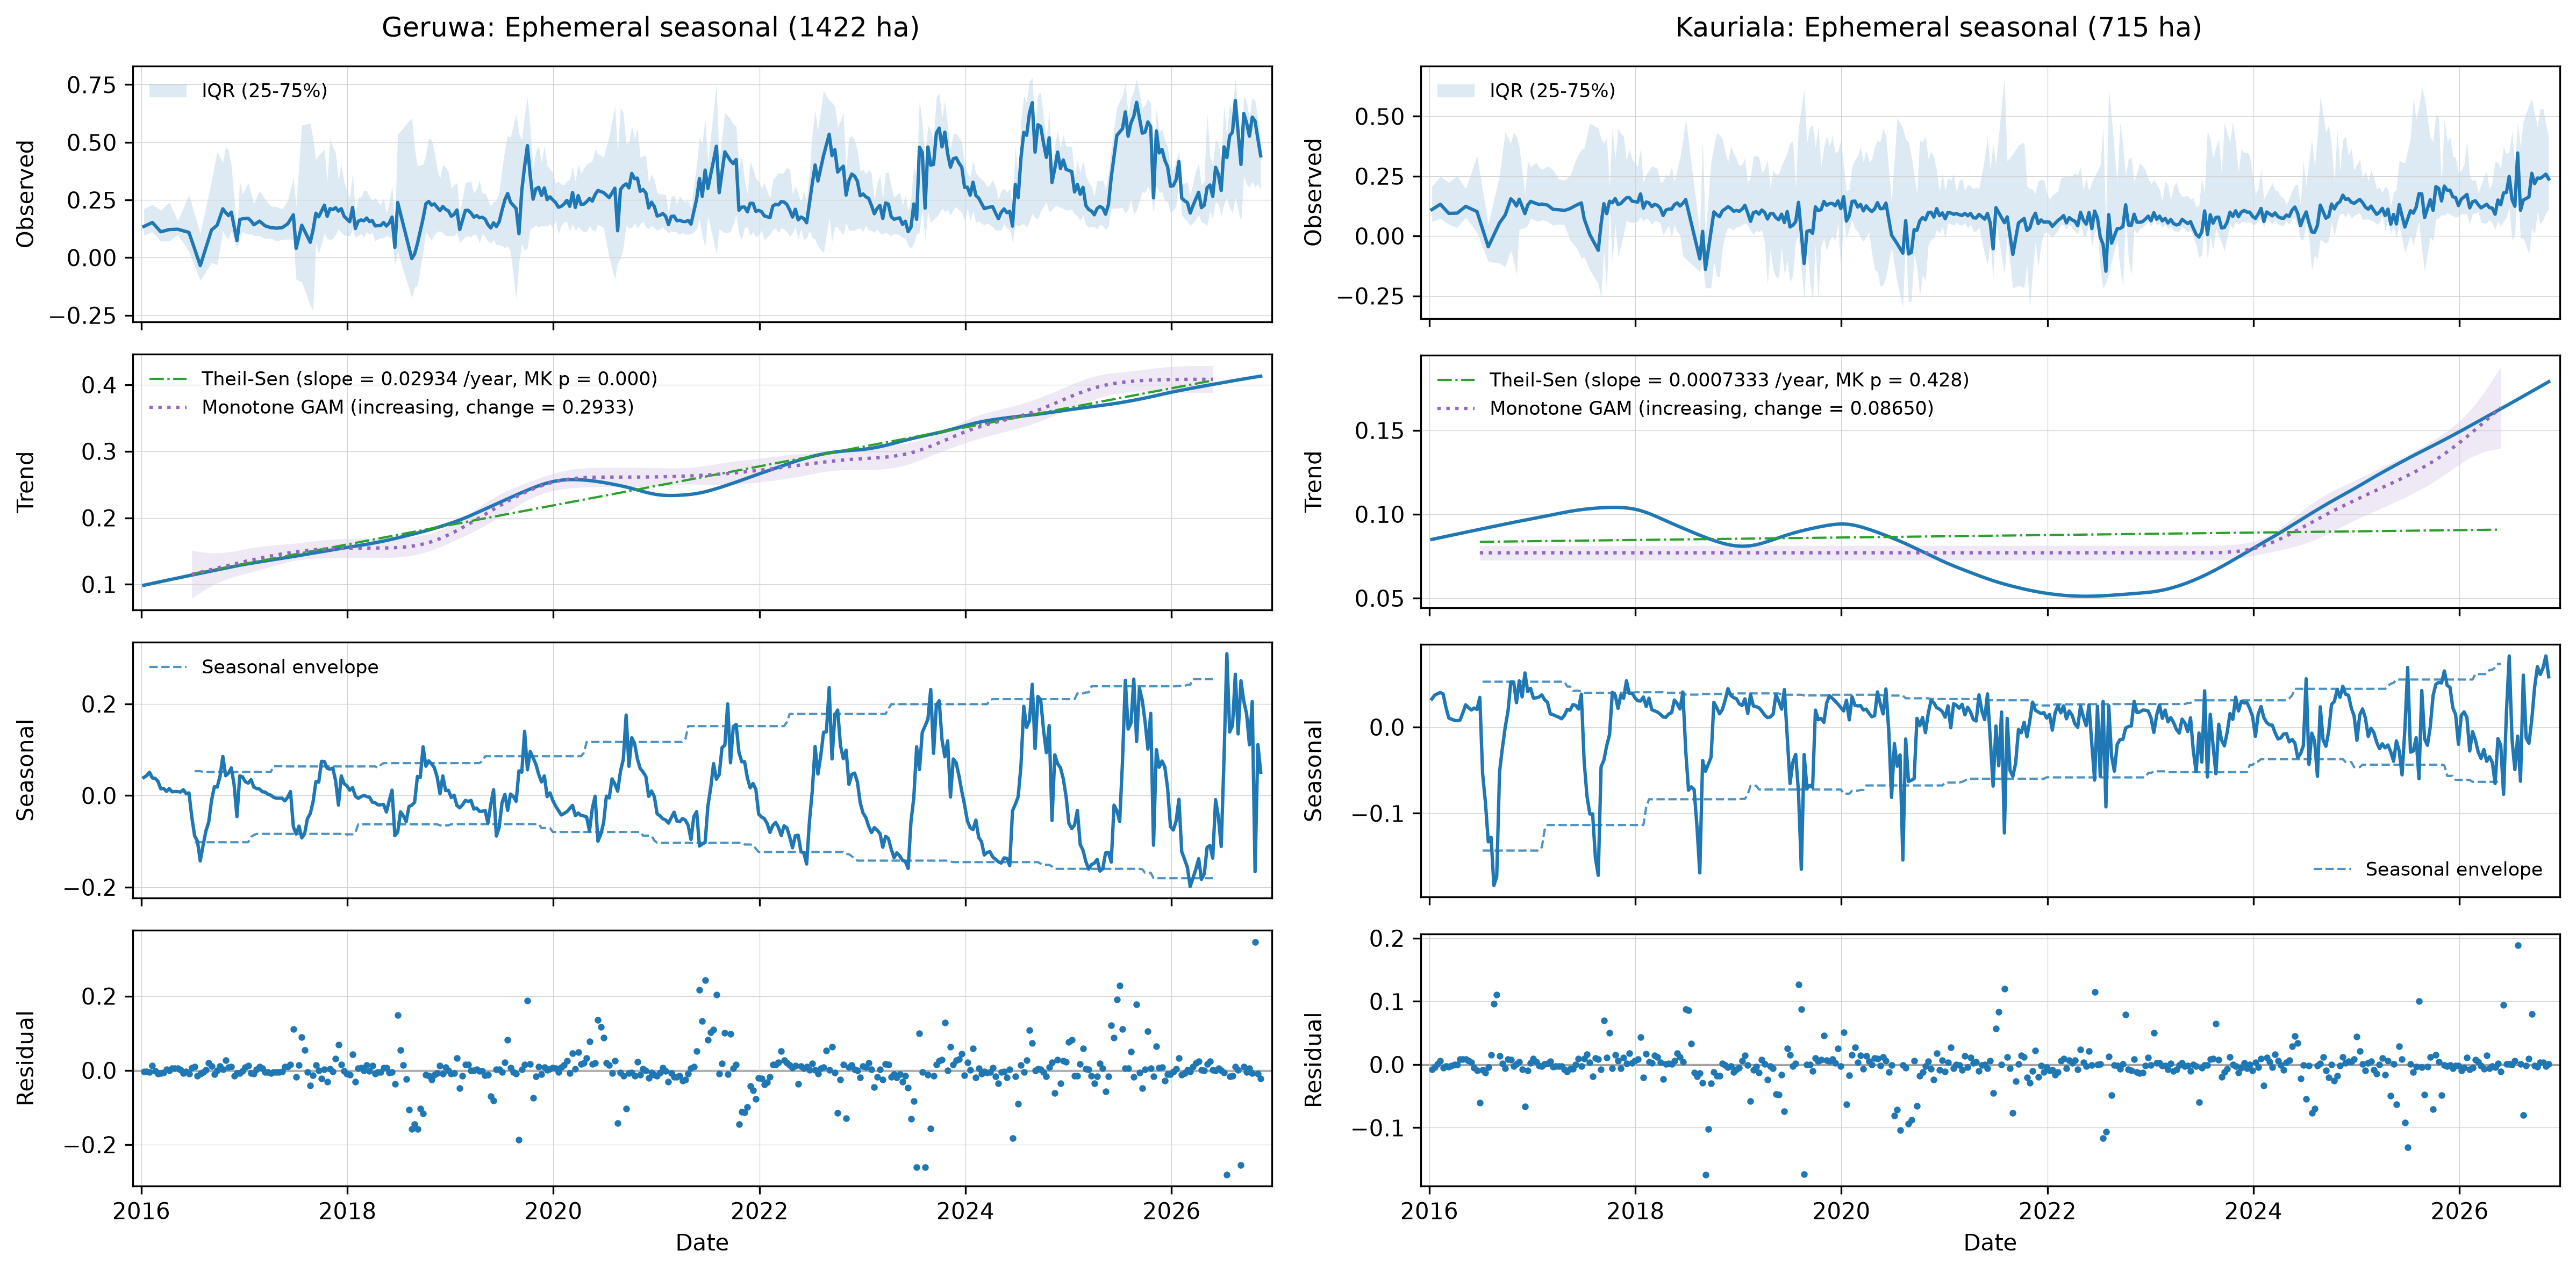

In [72]:
#| label: dat16-stl-lost
#| id: dat16
#| code-fold: show

compare_branches(10, "lost")

Although both areas belong to the same class, they show different profiles. In the Geruwa, the trend increased steadily, from about 0.10 in 2016 to 0.41 in 2026 (Theil-Sen slope 0.029 per year, Mann-Kendall p < 0.001). The seasonal component changed as well. In the first years, its amplitude was small, and the monsoon caused a short dip, but from about 2019 onwards, each monsoon shows an increasingly higher NDVI peak, followed by vegetation that dies back or is removed in the dry season. NDVI alone cannot tell whether this reflects more productive vegetation of the same type or a shift from short to tall grassland. In the Kauriala, the trend stayed between 0.05 and 0.10 until 2024 and only then increased, to about 0.18 at the end of 2026. The seasonal component shows clear monsoon dips in the first years, which became weaker later. Most of this area thus apparently remained bare or sparsely vegetated until recently.

The wide interquartile range (IQR) in both branches shows that the class is far from homogeneous. In the Geruwa, the upper quartile already reached 0.45–0.6 during the monsoon in the first years, while the median stayed around 0.2. Part of the area was thus already vegetated in 2016, and the rising median reflects a shift from a minority to a majority of vegetated pixels. In the Kauriala, the IQR is even wider, from below 0 during the monsoon, i.e., water, to over 0.4. The zone thus contains water, bare ground and vegetation, but more than half of it remains (nearly) bare. The transition class, which only describes the water history, therefore covers a much wider range of current conditions than its name suggests.

#### Areas that gained water

The classes 'new permanent', 'new seasonal' and 'seasonal to permanent' cover areas that had no water, or only seasonal water, in 1984, but more water in 2024. As representative class, we use 'new seasonal', which covers 449 ha in the Geruwa and 953 ha in the Kauriala.

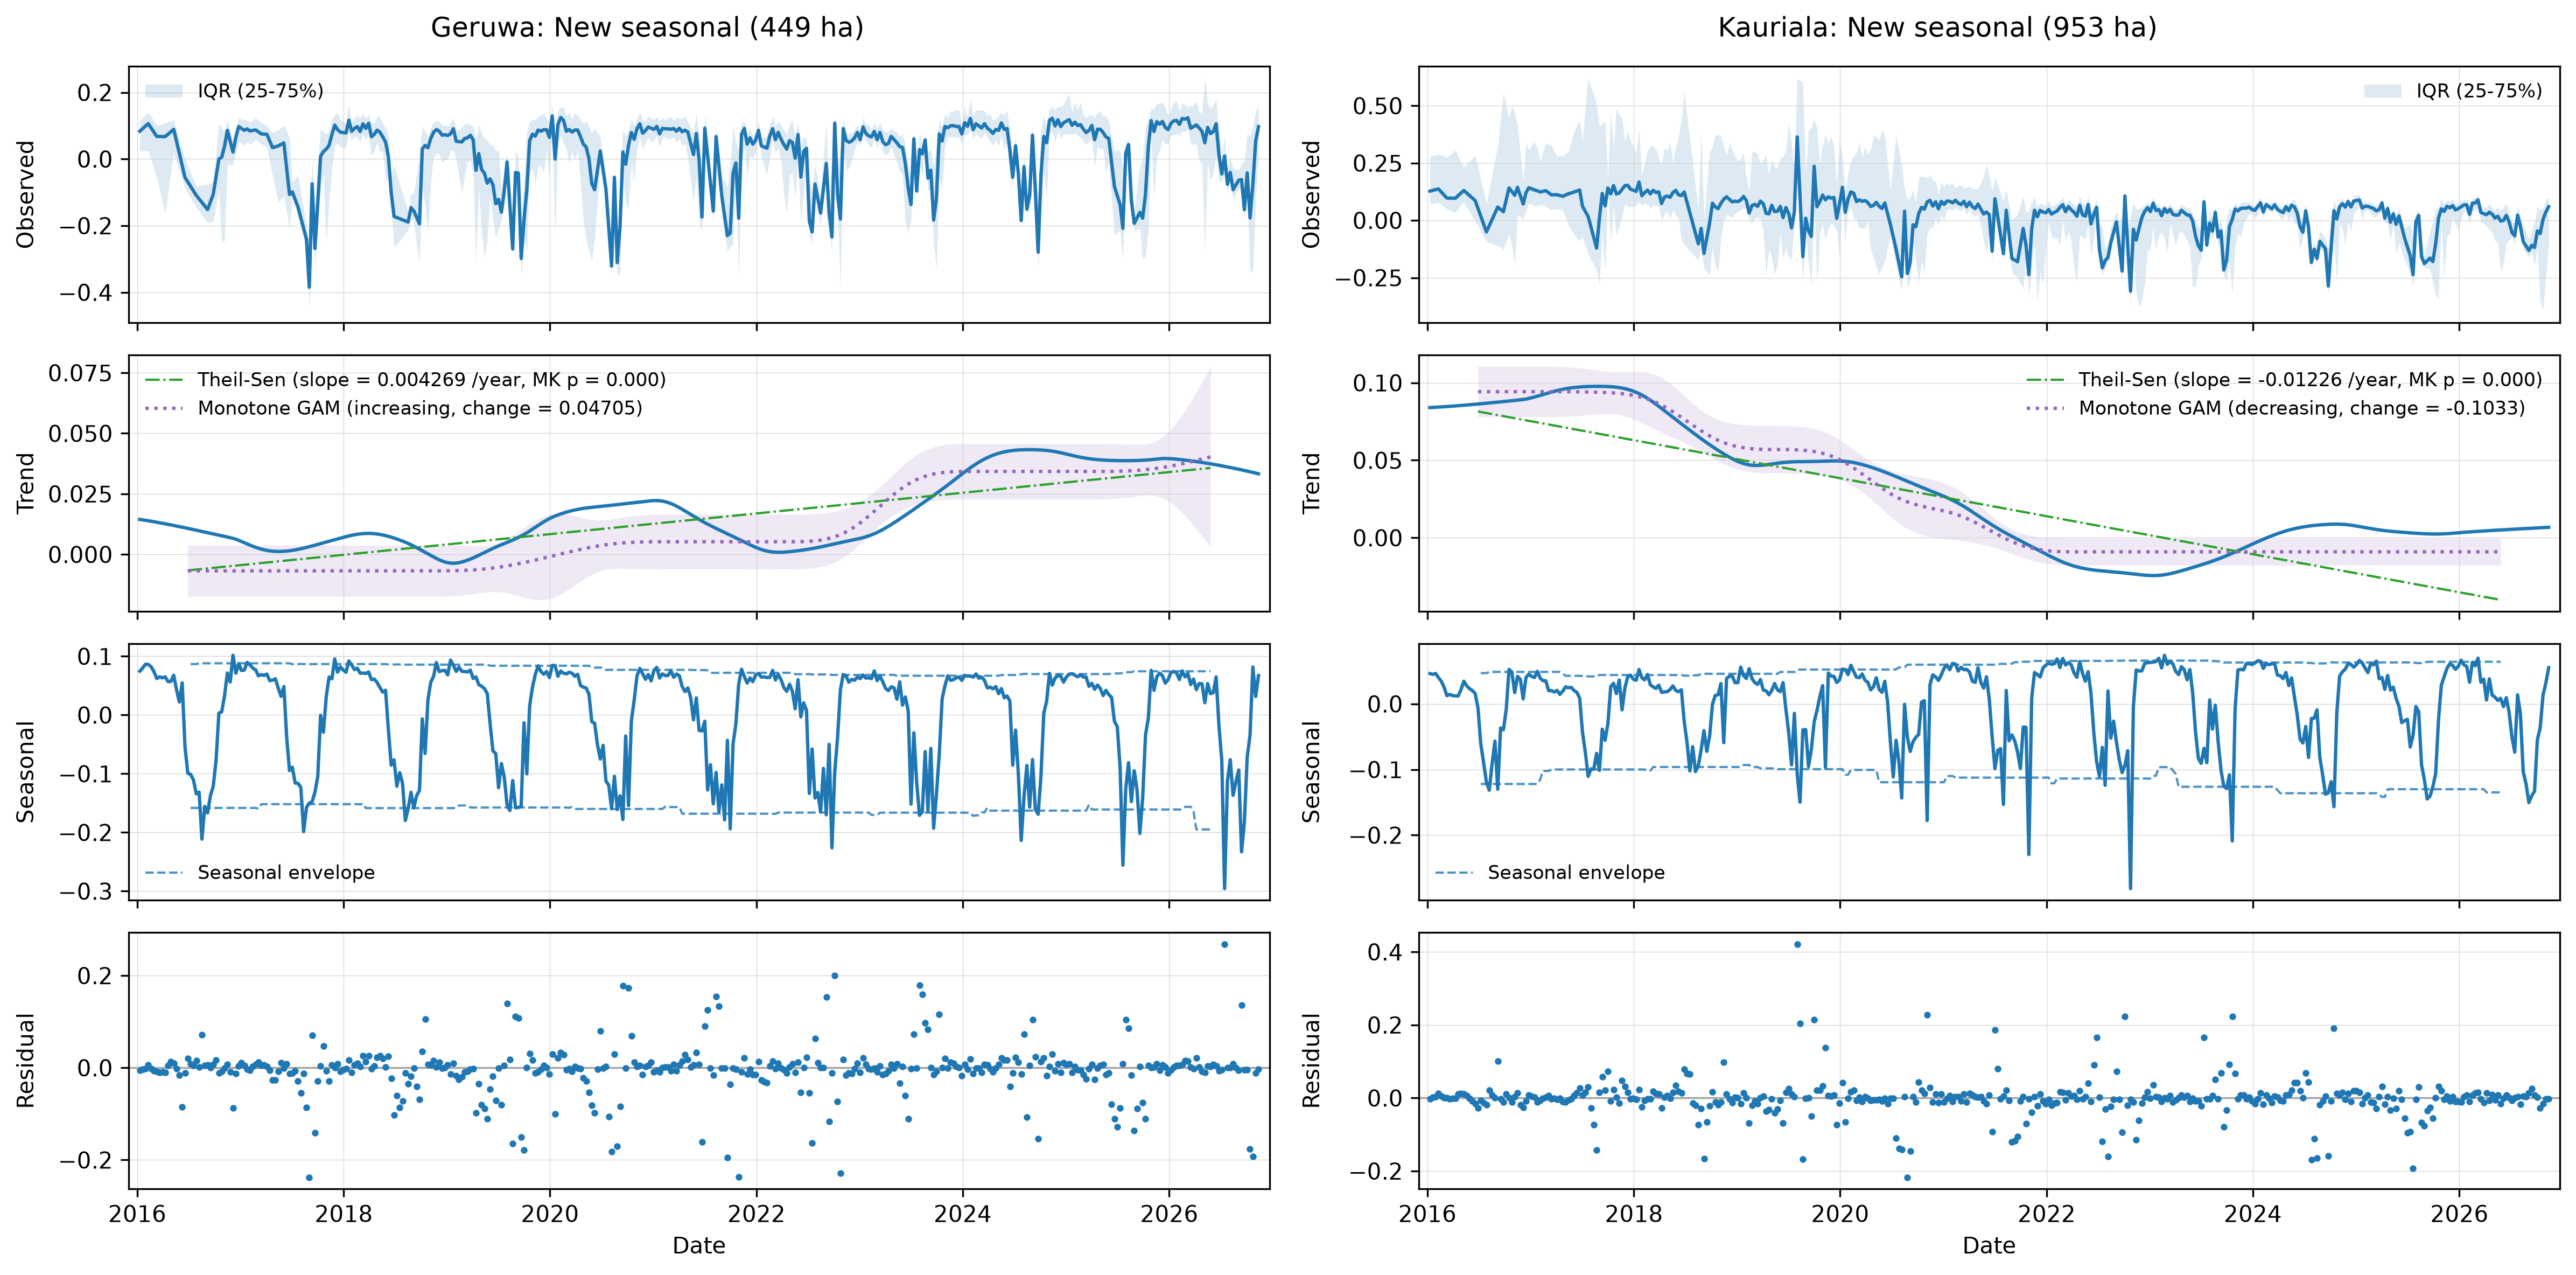

In [73]:
#| label: dat17-stl-gained
#| id: dat17
#| code-fold: show

compare_branches(5, "gained")

In the Geruwa, these areas show the profile of an active river bed throughout the period. The NDVI is around 0.1 in the dry season, with dips of −0.1 to −0.3 during the monsoon floods. It furthermore shows a relatively narrow IQR, and hardly any trend (0.004 per year). In the Kauriala, the trend decreased from about 0.09 to about −0.01, with most of the decrease happening between 2018 and 2022, after which it stabilizes. In the first years, the upper quartile reached 0.3–0.6 during the monsoon, showing that a considerable part of the zone was still vegetated. From about 2020, this upper part of the IQR band shrank, and by 2022 it had largely disappeared, while the monsoon dips became deeper. This suggests that a good part of the vegetation was lost and the zone was flooded more often. This is likely because the Kauriala carried more water. Since 2022, the profile is closer to that of the Geruwa. The two branches thus ended up with a similar profile, but along different paths. Along the Geruwa, these areas were already part of the active riverbed in 2016 (remember that the GSW series starts in 1984), while along the Kauriala, they became part of it during the study period.


#### Areas that remained water

The classes 'permanent', 'seasonal' and 'permanent to seasonal' cover areas that had water, for at least part of the year, in both 1984 and 2024. Together, they form the active river bed with the main channels and the bars and banks that are flooded during the monsoon. These may be bare or colonized by pioneer vegetation such as alluvial tall grassland dominated by *Saccharum spontaneum* ([Bijlmakers et al., 2023](https://doi.org/10.5194/bg-20-1113-2023)). As the water regime of these areas changed little, they serve as a reference. As representative class, we use 'seasonal', which covers 110 ha in the Geruwa and 68 ha in the Kauriala.

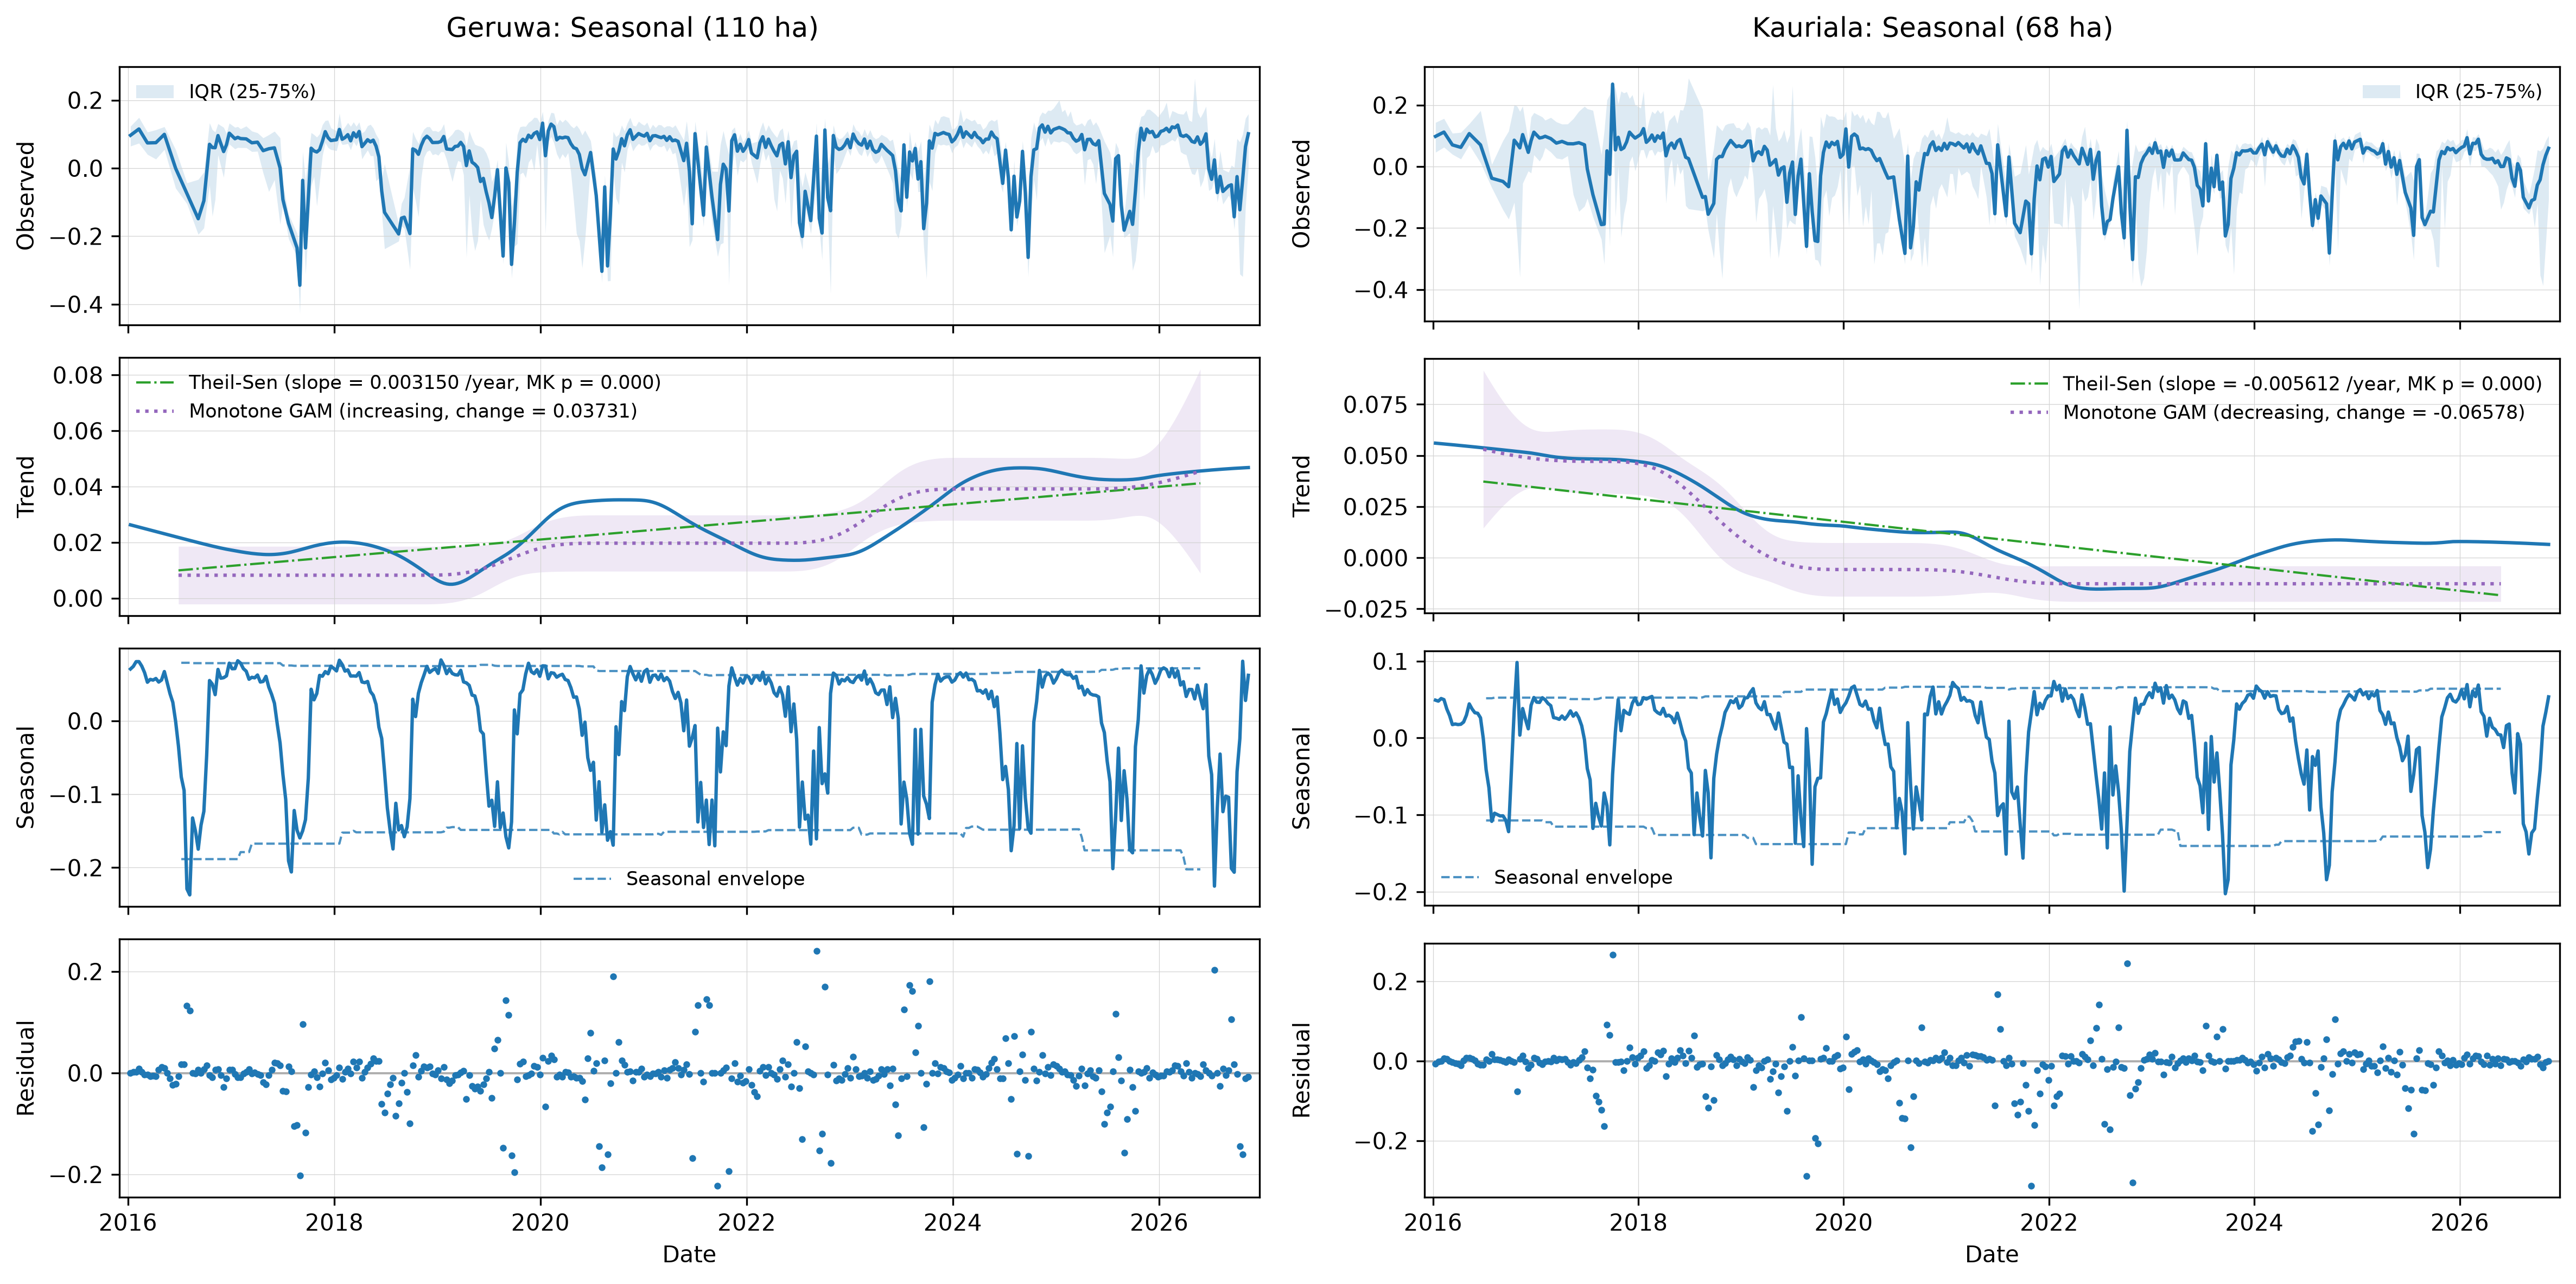

In [74]:
#| label: dat18-stl-water
#| id: dat18
#| code-fold: show

compare_branches(4, "water")

Both branches show a similar profile: NDVI around 0.05–0.1 in the dry season, with a narrow IQR, and dips to −0.2 or lower during the monsoon. These areas are thus largely bare, with little vegetation establishing between floods. The trend in the Geruwa hardly changed (0.003 per year). In the Kauriala, it decreased slightly in 2018–2019, around the same time the 'new seasonal' areas lost their vegetation (previous plot), and stayed nearly constant afterwards. 

Because the water regime of these areas changed little, they show what the NDVI profile of each branch looks like without a change in flow. These profiles are nearly the same in both branches. This suggests that other potential differentiating factors, such as the substrate of the riverbed, do not lead to different NDVI profiles. The clear differences in the other two groups are therefore more likely related to the shift of the flow from the Geruwa to the Kauriala.

#### All combinations

The code below creates the plots for all transition classes in both branches, which allows you to inspect all combinations. Some classes cover only a few hectares, e.g., seasonal to permanent in the Geruwa (7 ha). These consist mainly of pixels along class borders, so their time series should be interpreted with caution.

In [ ]:
#| label: dat19-stl-all
#| id: dat19
#| code-fold: show

for branch in ["Geruwa", "Kauriala"]:
    for value, _, label in gswe_classes:
        if (branch, value) in areas:
            stl_zone(branch, value, label)

## Discussion

### About the findings
The comparison shows that areas with similar hydrological patterns between 1984 and 2024 can have different vegetation dynamics (2016–2026). Areas that lost water became steadily greener along the Geruwa, while this is not the case in Kauriala until 2024. Areas that gained water along the Geruwa already had the profile that points at an active riverbed, while they lost their remaining vegetation between 2018 and 2022 along the Kauriala. The active river bed itself, used as a reference, shows similar profiles in both branches. These patterns agree with the shift of the flow from the Geruwa to the Kauriala after the 2009 flood ([Gautam et al., 2026](https://doi.org/10.5194/esurf-14-887-2026)), and with the expansion of alluvial tall grassland dominated by *Saccharum spontaneum* along the Geruwa since then ([Bijlmakers et al., 2023](https://doi.org/10.5194/bg-20-1113-2023)). The greening in the Geruwa comes mainly from higher monsoon peaks, while the dry-season values increased much less, possibly because the vegetation dies back, or is removed by grazing, cutting or burning.

Combining the two datasets thus proved useful. The STL decomposition separates the long-term change from the seasonal cycle, which in these areas is much larger. Changes in the seasonal component, such as a monsoon dip that turns into a monsoon peak, are as informative as the trend. Summarizing the NDVI per zone reduces noise, while the interquartile range shows how uniform a zone is. And because the whole analysis runs in GRASS, it is easy to repeat for other zones, or when new imagery becomes available.

### Limitations

The current approach has several limitations, foremost the short time series. Extending the analysis with the longer Landsat archive ([Wulder et al. 2016](https://doi.org/10.1016/j.rse.2015.11.032)) or the denser Harmonized Landsat and Sentinel-2 (HLS) series ([Claverie et al. 2018](https://doi.org/10.1016/j.rse.2018.09.002)) would provide a broader temporal perspective. This would require adapting the download and import steps and applying product-specific conversions from digital numbers (DNs) to surface reflectance, but the remainder of the pipeline would remain unchanged.

The GSW transition classes are derived from 30~m Landsat data and summarize changes between the first and last year, comparing water states only. That means that, except for the two ephemeral-water classes, pixels assigned to the same transition class may therefore have followed different trajectories. This is, in fact, what our results show. A single class may therefore contain areas with very different histories and present-day land cover. Here, these classes primarily serve to demonstrate the approach. Any raster or vector map could instead define the areas of interest, including specific land-cover classes, management units, or buffer zones around the active channel.

For the trends, the p-values should be interpreted with much care. With this many observations, even minimal trends are significant. The Mann-Kendall test furthermore assumes independent observations, which we rarely see in time series. In addition, the Theil-Sen line misses changes late in the series. The size and timing of the change, shown by the trend component and the monotone GAM, are therefore more informative than the p-value.

### Merits of the workflow

The GRASS temporal framework provides a solid basis to store and manage time series of raster maps. Each map in a space-time raster dataset (STRDS) carries its timestamp and metadata, so tools can select, combine or aggregate maps by time, without the user having to keep track of file names and dates. Much of the work is thus handled by the framework, and the code needed for an analysis stays short. In this notebook, for example, computing the NDVI of all scenes took a single call of *t.rast.mapcalc*, and combining the scenes of each day a single call of *t.rast.aggregate*, both running in parallel.

*t.rast.stl* shows how a complete analysis pipeline can be wrapped in a single tool. It extracts the time series of a point or area, resamples it to a regular time step, decomposes it with STL, fits trend lines and tests, and plots the results. Its options give a fair amount of flexibility, e.g., in the statistic, the time step, and the trend tests and plot elements to include. This saves coding and helps to develop reproducible code. Like any other GRASS tool, *t.rast.stl* can be run from the command line, Python or R, and thus be built into a larger analysis, as we did here for the transition classes. At the same time, it can be used interactively in the graphical user interface, by selecting points on the map. This makes it equally suited to rapid exploration by users without programming experience, such as ecologists and practitioners, who want to see how the vegetation at a site of interest has changed.